In [3]:
import pandas as pd
import time

file = "SpectrumData_2021Y.xlsx"

start = time.time()
print("Loading trainSet...", flush=True)

trainSet = pd.read_excel(file, sheet_name="trainSet")

print(
    f"Loaded trainSet: {trainSet.shape} "
    f"in {time.time() - start:.1f} seconds",
    flush=True
)

Loading wavelength...
Loaded wavelength: (224, 3) in 0.0 seconds
Loading darkcurrent...
Loaded darkcurrent: (640, 224) in 2.3 seconds
Loading trainSet...
Loaded trainSet: (50000, 227) in 37.1 seconds


In [5]:
# Examine coordinate repetition and grid coverage to help determine whether
# the dataset represents one image or multiple images. Repeated coordinates
# could indicate overlapping images or repeated measurements; missing positions
# could indicate that background pixels were excluded.

coords = trainSet[["coord_lateral", "coord_driving"]].dropna()

print(f"Rows with missing coordinates: {len(trainSet) - len(coords):,}")

unique_coords = coords.drop_duplicates()
counts = coords.value_counts()

print(f"Unique coordinate pairs: {len(unique_coords):,}")
print(f"Coordinate pairs appearing more than once: {(counts > 1).sum():,}")
print(f"Extra rows at repeated coordinates: {len(coords) - len(unique_coords):,}")

for column in coords.columns:
    print(
        f"{column}: min = {coords[column].min()}, "
        f"max = {coords[column].max()}"
    )

# Count grid positions mathematically without constructing a large matrix.
# A pixel grid is assumed to use integer coordinates spaced one unit apart.
if coords.empty:
    print("No valid coordinates found.")
elif (coords % 1 == 0).all().all():
    lateral_size = int(coords["coord_lateral"].max()
                       - coords["coord_lateral"].min() + 1)
    driving_size = int(coords["coord_driving"].max()
                       - coords["coord_driving"].min() + 1)

    expected = lateral_size * driving_size
    missing = expected - len(unique_coords)

    print(f"\nGrid dimensions: {lateral_size:,} lateral × {driving_size:,} driving")
    print(f"Possible positions within these bounds: {expected:,}")
    print(f"Missing positions: {missing:,}")
    print(f"Grid coverage: {len(unique_coords) / expected:.2%}")
    print(f"All positions present: {missing == 0}")
else:
    print("\nCoordinates are not all integers; grid spacing needs checking.")


Rows with missing coordinates: 0
Unique coordinate pairs: 8,905
Coordinate pairs appearing more than once: 8,717
Extra rows at repeated coordinates: 41,095
coord_lateral: min = 33, max = 549
coord_driving: min = 93, max = 4779

Grid dimensions: 517 lateral × 4,687 driving
Possible positions within these bounds: 2,423,179
Missing positions: 2,414,274
Grid coverage: 0.37%
All positions present: False


In [6]:
# Check whether sampled positions form spatial clusters by finding
# immediate neighbours on an assumed unit-spaced pixel grid.

positions = set(
    trainSet[["coord_lateral", "coord_driving"]]
    .dropna()
    .itertuples(index=False, name=None)
)

directions = {
    "Lateral": [(1, 0), (-1, 0)],
    "Driving": [(0, 1), (0, -1)],
    "Any (including diagonal)": [
        (dx, dy)
        for dx in (-1, 0, 1)
        for dy in (-1, 0, 1)
        if (dx, dy) != (0, 0)
    ],
}

for name, offsets in directions.items():
    count = sum(
        any((x + dx, y + dy) in positions for dx, dy in offsets)
        for x, y in positions
    )
    percentage = 100 * count / len(positions) if positions else 0
    print(f"{name}: {count:,} positions have neighbours ({percentage:.2f}%)")

# Show up to 10 neighbouring pairs without counting each pair twice.
examples = []
for x, y in sorted(positions):
    for dx, dy in [(1, 0), (0, 1)]:
        neighbour = (x + dx, y + dy)
        if neighbour in positions:
            examples.append(((x, y), neighbour))
            if len(examples) == 10:
                break
    if len(examples) == 10:
        break

print("\nExample neighbouring pairs (lateral, driving):")
for pair in examples:
    print(pair)

Lateral: 8,786 positions have neighbours (98.66%)
Driving: 8,779 positions have neighbours (98.59%)
Any (including diagonal): 8,905 positions have neighbours (100.00%)

Example neighbouring pairs (lateral, driving):
((33, 140), (34, 140))
((34, 137), (35, 137))
((34, 137), (34, 138))
((34, 138), (35, 138))
((34, 138), (34, 139))
((34, 139), (35, 139))
((34, 139), (34, 140))
((34, 140), (35, 140))
((34, 140), (34, 141))
((34, 141), (35, 141))


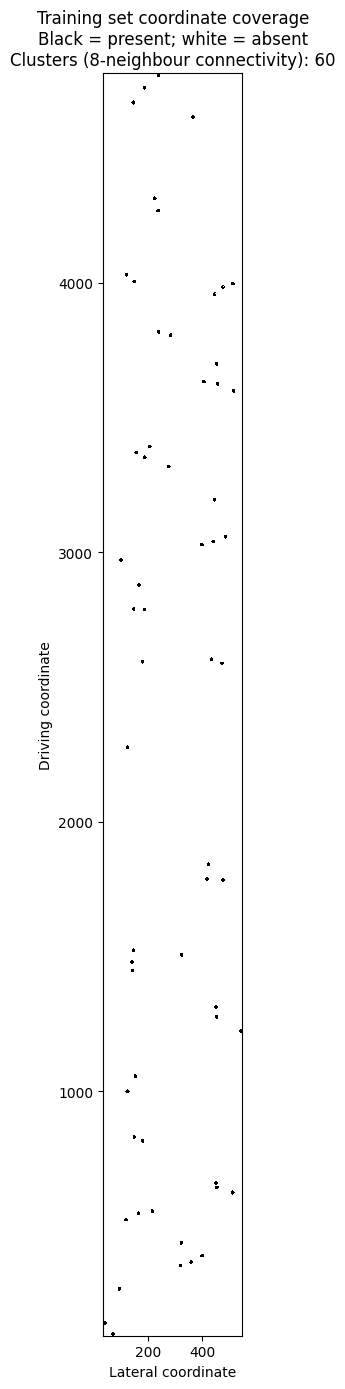

Clusters: 60
Saved: /Users/williamronan/PythonTools/HyperspectralPVCSort/images/imageShadow.png


In [8]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from scipy.ndimage import label

# Map sampled coordinates and count spatially connected clusters.
# Repeated coordinates occupy the same cell; diagonal neighbours connect.
coords = (
    trainSet[["coord_lateral", "coord_driving"]]
    .dropna()
    .drop_duplicates()
)

if not (coords % 1 == 0).all().all():
    raise ValueError("Coordinates must be integers to construct a pixel matrix.")

coords = coords.astype(int)

lateral_min = coords["coord_lateral"].min()
lateral_max = coords["coord_lateral"].max()
driving_min = coords["coord_driving"].min()
driving_max = coords["coord_driving"].max()

imageShadow = np.zeros(
    (driving_max - driving_min + 1, lateral_max - lateral_min + 1),
    dtype=np.uint8
)

imageShadow[
    coords["coord_driving"].to_numpy() - driving_min,
    coords["coord_lateral"].to_numpy() - lateral_min
] = 1

# Count connected components using horizontal, vertical, and diagonal links.
_, cluster_count = label(
    imageShadow,
    structure=np.ones((3, 3), dtype=int)
)

image_dir = Path("images")
image_dir.mkdir(parents=True, exist_ok=True)
output_path = image_dir / "imageShadow.png"

fig, ax = plt.subplots(figsize=(7, 14))
ax.imshow(
    imageShadow,
    cmap=ListedColormap(["white", "black"]),
    vmin=0,
    vmax=1,
    origin="lower",
    interpolation="nearest",
    aspect="equal",
    extent=(
        lateral_min - 0.5, lateral_max + 0.5,
        driving_min - 0.5, driving_max + 0.5
    )
)

ax.set_xlabel("Lateral coordinate")
ax.set_ylabel("Driving coordinate")
ax.set_title(
    f"Training set coordinate coverage\n"
    f"Black = present; white = absent\n"
    f"Clusters (8-neighbour connectivity): {cluster_count:,}"
)

fig.tight_layout()
fig.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Clusters: {cluster_count:,}")
print(f"Saved: {output_path.resolve()}")

Cluster size statistics (unique coordinate positions):
count     60.00
mean     148.42
std        0.81
min      146.00
25%      148.00
50%      149.00
75%      149.00
max      149.00
Name: unique_positions, dtype: float64

Size standard deviation / mean: 0.5%
Single-category clusters: 60 / 60
Clusters with multiple categories: 0
Rows with missing category labels: 0


,unique_positions,rows,category_count,dominant_category,purity_percent,missing_labels,single_category
cluster,,,,,,,
1,149,845,1,PET,100.0,0,True
2,149,820,1,PET,100.0,0,True
3,149,851,1,PVC,100.0,0,True
4,148,770,1,PET,100.0,0,True
5,146,791,1,PET,100.0,0,True
6,148,863,1,PET,100.0,0,True
7,148,849,1,PVC,100.0,0,True
8,148,804,1,PET,100.0,0,True
9,149,863,1,PET,100.0,0,True



Category counts per cluster (all measurement rows):


class_id,PE,PP,PET,PS,PVC
cluster,,,,,
1,0,0,845,0,0
2,0,0,820,0,0
3,0,0,0,0,851
4,0,0,770,0,0
5,0,0,791,0,0
6,0,0,863,0,0
7,0,0,0,0,849
8,0,0,804,0,0
9,0,0,863,0,0


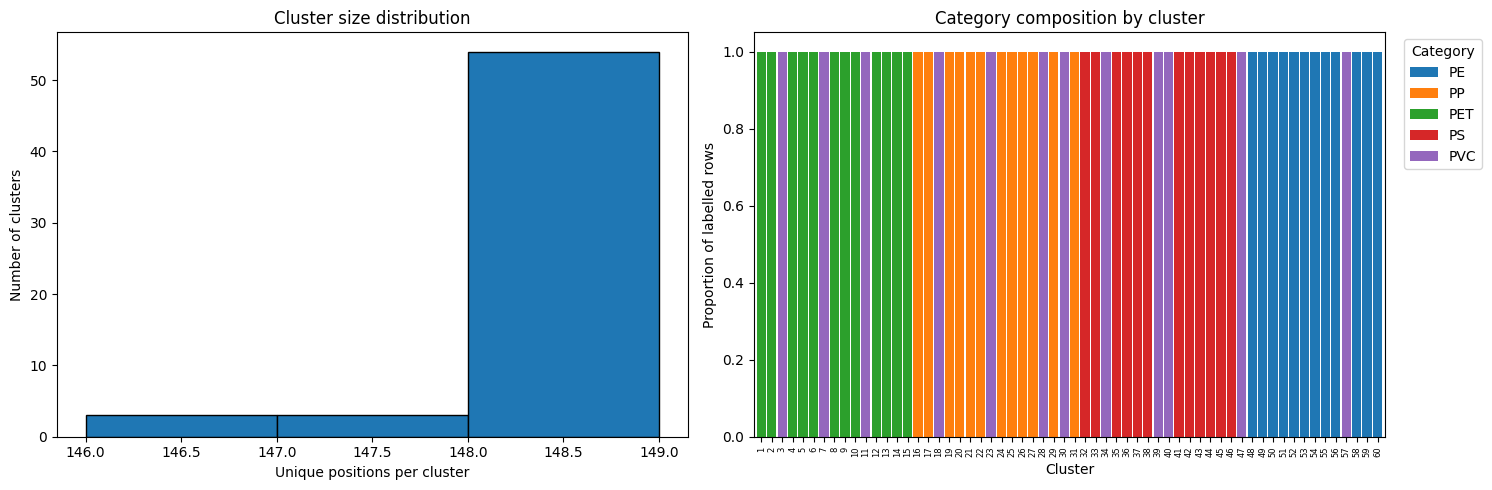

Saved: /Users/williamronan/PythonTools/HyperspectralPVCSort/images/clusterAnalysis.png


In [9]:
import pandas as pd
from scipy.ndimage import label

# Compare cluster sizes and check whether each spatial cluster contains
# one polymer category or a mixture of categories.
cluster_labels, cluster_count = label(
    imageShadow,
    structure=np.ones((3, 3), dtype=int)
)

rows = trainSet[
    ["coord_lateral", "coord_driving", "class_id"]
].dropna(subset=["coord_lateral", "coord_driving"]).copy()

rows["cluster"] = cluster_labels[
    rows["coord_driving"].astype(int).to_numpy() - driving_min,
    rows["coord_lateral"].astype(int).to_numpy() - lateral_min
]

class_names = {1: "PE", 2: "PP", 3: "PET", 4: "PS", 5: "PVC"}

# Size uses unique positions so repeated coordinates do not inflate it.
sizes = (
    rows.drop_duplicates(["coord_lateral", "coord_driving"])
    .groupby("cluster")
    .size()
    .rename("unique_positions")
)

# Category counts include every measurement at each coordinate.
category_counts = pd.crosstab(rows["cluster"], rows["class_id"])

summary = sizes.to_frame()
summary["rows"] = rows.groupby("cluster").size()
summary["category_count"] = (category_counts > 0).sum(axis=1)
summary["dominant_category"] = category_counts.idxmax(axis=1).map(class_names)
summary["purity_percent"] = (
    category_counts.max(axis=1) / category_counts.sum(axis=1) * 100
)
summary["missing_labels"] = (
    rows["class_id"].isna().groupby(rows["cluster"]).sum()
)
summary["single_category"] = (
    summary["category_count"].eq(1) & summary["missing_labels"].eq(0)
)

print("Cluster size statistics (unique coordinate positions):")
print(sizes.describe().round(2))
print(f"\nSize standard deviation / mean: {sizes.std() / sizes.mean():.1%}")
print(f"Single-category clusters: {summary['single_category'].sum()} / {cluster_count}")
print(f"Clusters with multiple categories: {(summary['category_count'] > 1).sum()}")
print(f"Rows with missing category labels: {rows['class_id'].isna().sum()}")

display(summary.round(2))

print("\nCategory counts per cluster (all measurement rows):")
display(category_counts.rename(columns=class_names))

# Plot size distribution and category composition.
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].hist(sizes, bins="auto", edgecolor="black")
axes[0].set_xlabel("Unique positions per cluster")
axes[0].set_ylabel("Number of clusters")
axes[0].set_title("Cluster size distribution")

category_proportions = category_counts.div(
    category_counts.sum(axis=1), axis=0
).rename(columns=class_names)

category_proportions.plot(
    kind="bar", stacked=True, ax=axes[1], width=0.9
)
axes[1].set_xlabel("Cluster")
axes[1].set_ylabel("Proportion of labelled rows")
axes[1].set_title("Category composition by cluster")
axes[1].tick_params(axis="x", labelsize=6)
axes[1].legend(title="Category", bbox_to_anchor=(1.02, 1))

fig.tight_layout()
output_path = image_dir / "clusterAnalysis.png"
fig.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Saved: {output_path.resolve()}")

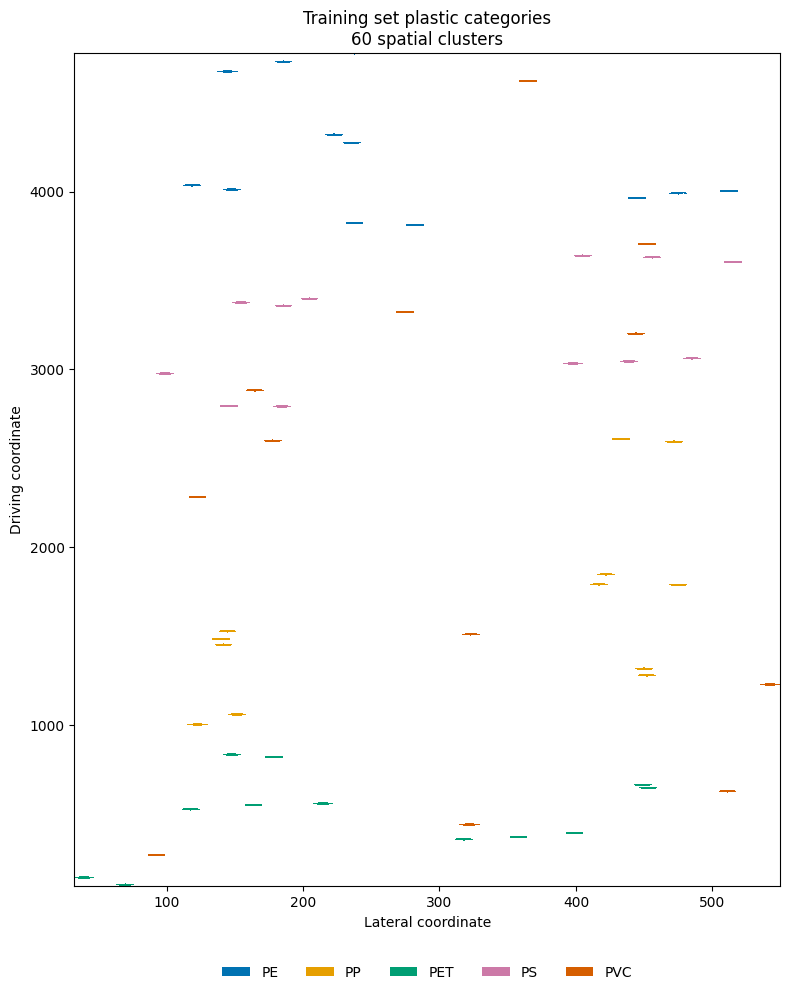

Saved: /Users/williamronan/PythonTools/HyperspectralPVCSort/images/imagePlasticTypes.png


In [10]:
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch

# Colour sampled positions by polymer type to inspect the spatial arrangement.
# Coordinates are used only for visualization, not as model inputs.
class_names = {1: "PE", 2: "PP", 3: "PET", 4: "PS", 5: "PVC"}
class_colours = {
    1: "#0072B2",
    2: "#E69F00",
    3: "#009E73",
    4: "#CC79A7",
    5: "#D55E00"
}

coords = trainSet[
    ["coord_lateral", "coord_driving", "class_id"]
].dropna().drop_duplicates()

# Verify that repeated positions have consistent category labels.
if coords.groupby(
    ["coord_lateral", "coord_driving"]
)["class_id"].nunique().gt(1).any():
    raise ValueError("Some coordinates have conflicting category labels.")

coords = coords.astype(int)

lateral_min = coords["coord_lateral"].min()
lateral_max = coords["coord_lateral"].max()
driving_min = coords["coord_driving"].min()
driving_max = coords["coord_driving"].max()

plastic_image = np.zeros(
    (driving_max - driving_min + 1, lateral_max - lateral_min + 1),
    dtype=np.uint8
)

plastic_image[
    coords["coord_driving"].to_numpy() - driving_min,
    coords["coord_lateral"].to_numpy() - lateral_min
] = coords["class_id"].to_numpy()

cmap = ListedColormap(
    ["white"] + [class_colours[i] for i in range(1, 6)]
)
norm = BoundaryNorm(np.arange(-0.5, 6.5, 1), cmap.N)

fig, ax = plt.subplots(figsize=(8, 10))

ax.imshow(
    plastic_image,
    cmap=cmap,
    norm=norm,
    origin="lower",
    interpolation="nearest",
    aspect="auto",  # Fill a page-friendly rectangle.
    extent=(
        lateral_min - 0.5, lateral_max + 0.5,
        driving_min - 0.5, driving_max + 0.5
    )
)

ax.set_xlabel("Lateral coordinate")
ax.set_ylabel("Driving coordinate")
ax.set_title(
    f"Training set plastic categories\n"
    f"{cluster_count} spatial clusters"
)

ax.legend(
    handles=[
        Patch(facecolor=class_colours[i], label=class_names[i])
        for i in range(1, 6)
    ],
    loc="upper center",
    bbox_to_anchor=(0.5, -0.08),
    ncol=5,
    frameon=False
)

image_dir = Path("images")
image_dir.mkdir(parents=True, exist_ok=True)
output_path = image_dir / "imagePlasticTypes.png"

fig.tight_layout()
fig.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Saved: {output_path.resolve()}")

In [12]:
for name, frame in [
    ("wavelength", wavelength),
    ("darkcurrent", darkcurrent)
]:
    print(f"\n{name} — shape: {frame.shape}")
    print("Column names:", frame.columns.tolist())
    display(frame.head(8))
    display(frame.tail(3))


wavelength — shape: (224, 3)
Column names: ['channel', 'wavelength', 'fwhm']


,channel,wavelength,fwhm
0,1,932.82,3.52
1,2,936.33,3.52
2,3,939.85,3.52
3,4,943.37,3.52
4,5,946.88,3.52
5,6,950.40,3.52
6,7,953.91,3.52
7,8,957.43,3.52


,channel,wavelength,fwhm
221,222,1712.97,3.54
222,223,1716.52,3.55
223,224,1720.06,3.55



darkcurrent — shape: (640, 224)
Column names: ['ch.1', 'ch.2', 'ch.3', 'ch.4', 'ch.5', 'ch.6', 'ch.7', 'ch.8', 'ch.9', 'ch.10', 'ch.11', 'ch.12', 'ch.13', 'ch.14', 'ch.15', 'ch.16', 'ch.17', 'ch.18', 'ch.19', 'ch.20', 'ch.21', 'ch.22', 'ch.23', 'ch.24', 'ch.25', 'ch.26', 'ch.27', 'ch.28', 'ch.29', 'ch.30', 'ch.31', 'ch.32', 'ch.33', 'ch.34', 'ch.35', 'ch.36', 'ch.37', 'ch.38', 'ch.39', 'ch.40', 'ch.41', 'ch.42', 'ch.43', 'ch.44', 'ch.45', 'ch.46', 'ch.47', 'ch.48', 'ch.49', 'ch.50', 'ch.51', 'ch.52', 'ch.53', 'ch.54', 'ch.55', 'ch.56', 'ch.57', 'ch.58', 'ch.59', 'ch.60', 'ch.61', 'ch.62', 'ch.63', 'ch.64', 'ch.65', 'ch.66', 'ch.67', 'ch.68', 'ch.69', 'ch.70', 'ch.71', 'ch.72', 'ch.73', 'ch.74', 'ch.75', 'ch.76', 'ch.77', 'ch.78', 'ch.79', 'ch.80', 'ch.81', 'ch.82', 'ch.83', 'ch.84', 'ch.85', 'ch.86', 'ch.87', 'ch.88', 'ch.89', 'ch.90', 'ch.91', 'ch.92', 'ch.93', 'ch.94', 'ch.95', 'ch.96', 'ch.97', 'ch.98', 'ch.99', 'ch.100', 'ch.101', 'ch.102', 'ch.103', 'ch.104', 'ch.105', 'ch.106', 

,ch.1,ch.2,ch.3,ch.4,ch.5,ch.6,ch.7,ch.8,ch.9,ch.10,...,ch.215,ch.216,ch.217,ch.218,ch.219,ch.220,ch.221,ch.222,ch.223,ch.224
0,241,239,238,240,238,240,242,243,241,242,...,261,259,262,264,262,260,261,265,266,266
1,229,227,227,228,225,226,228,228,226,226,...,248,246,250,252,251,249,253,255,257,257
2,227,225,227,226,226,224,225,226,224,226,...,225,225,225,227,226,226,227,225,228,229
3,226,226,225,225,226,227,225,225,224,226,...,225,226,226,228,228,226,226,226,227,228
4,225,227,225,225,228,227,227,226,225,225,...,225,225,225,226,227,227,228,227,226,226
5,227,225,225,226,228,226,228,226,226,224,...,226,227,226,225,227,227,228,227,226,226
6,228,225,227,227,224,226,227,225,226,225,...,226,226,225,225,226,226,227,226,226,226
7,227,227,228,228,224,225,227,225,229,227,...,226,225,226,227,228,227,226,226,228,228


,ch.1,ch.2,ch.3,ch.4,ch.5,ch.6,ch.7,ch.8,ch.9,ch.10,...,ch.215,ch.216,ch.217,ch.218,ch.219,ch.220,ch.221,ch.222,ch.223,ch.224
637,225,226,222,229,225,227,229,228,226,225,...,228,230,226,227,228,226,232,231,229,228
638,227,227,225,228,229,227,228,227,227,225,...,262,261,265,261,260,259,259,262,262,262
639,227,227,228,229,228,225,223,228,227,230,...,262,261,265,261,260,259,259,262,262,262


Wavelength range: 932.82–1720.06 nm
Constant spectra excluded from normalized averages: 0


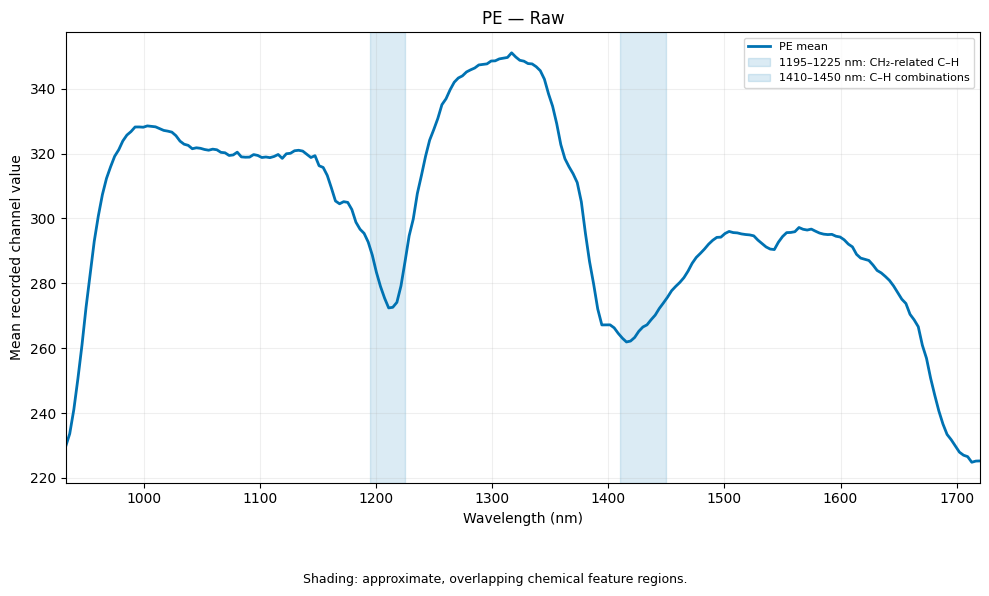

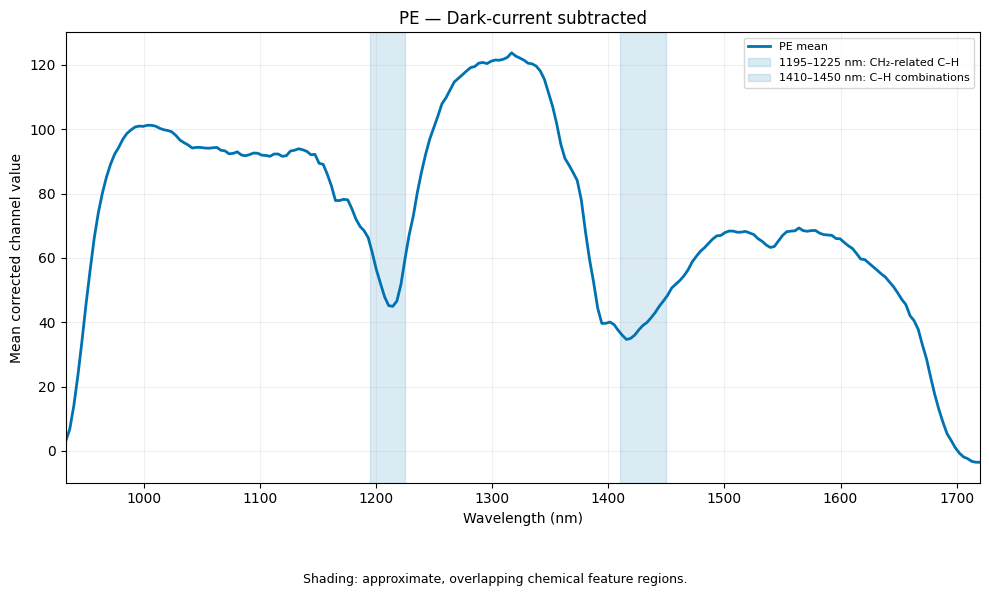

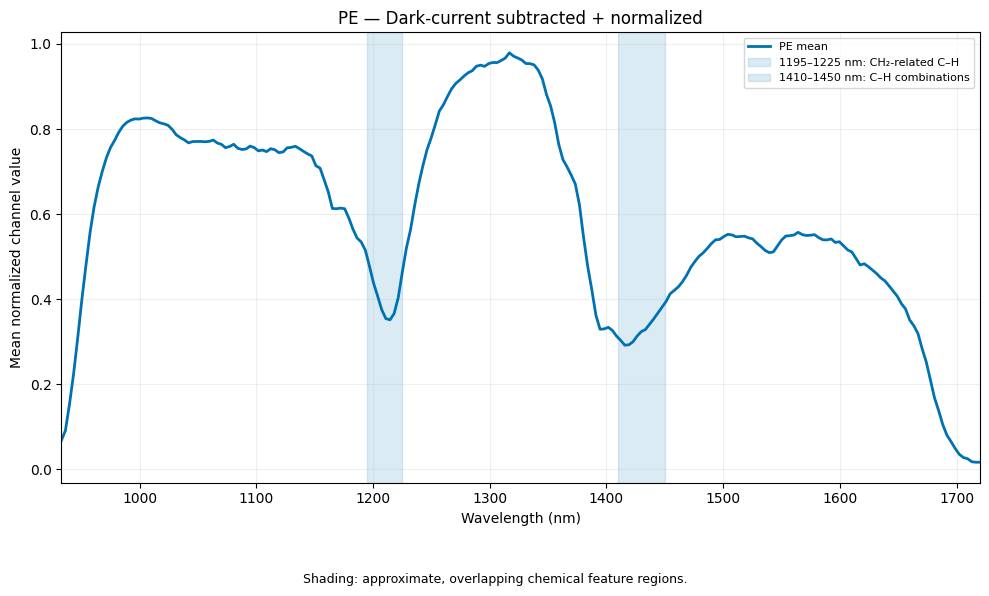

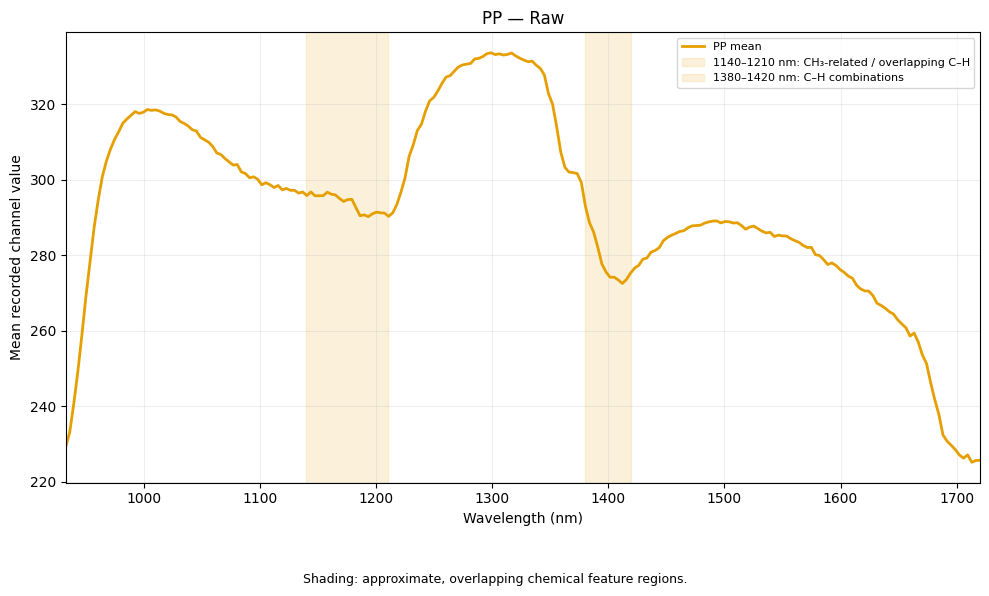

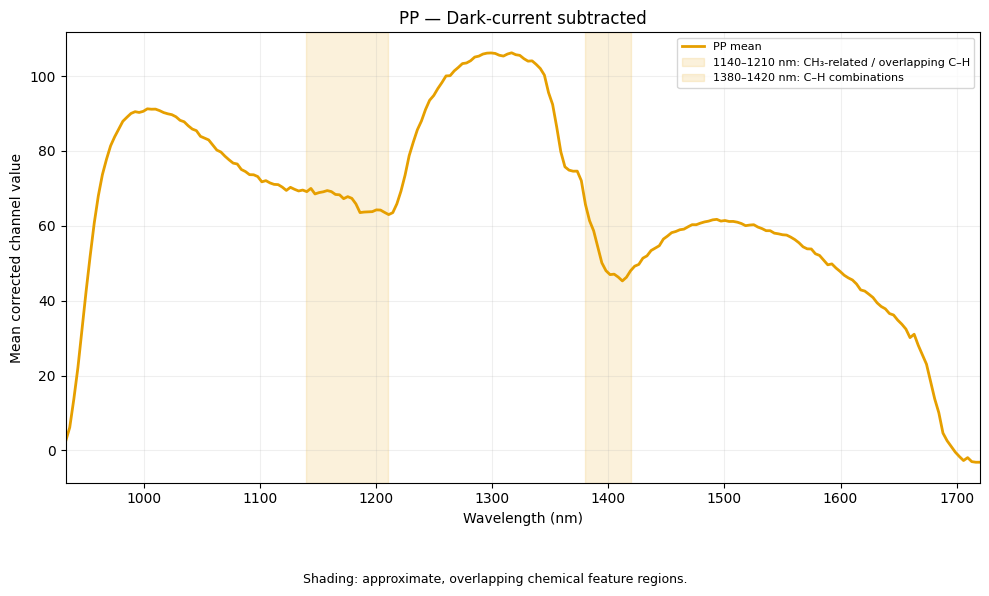

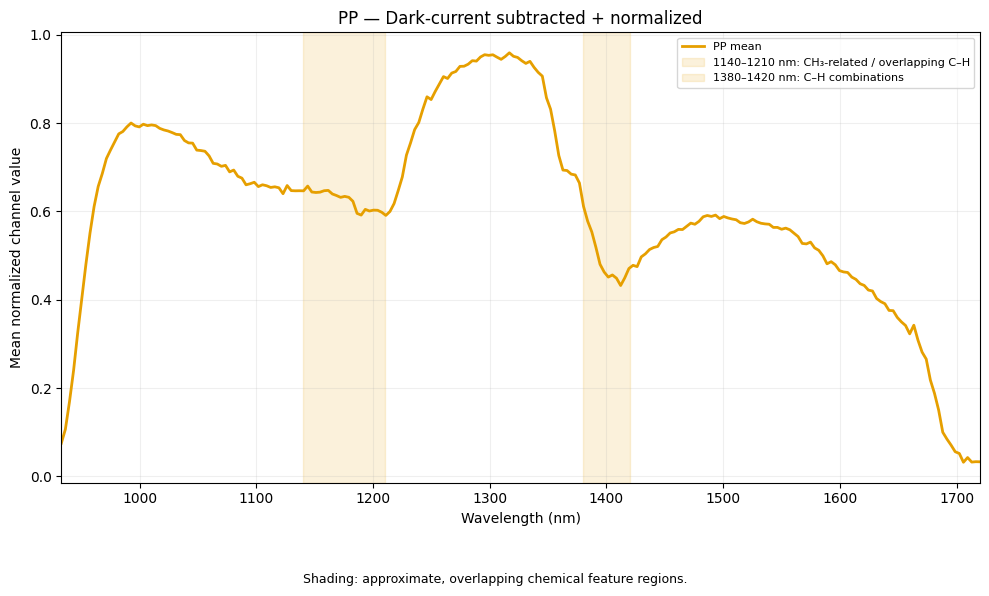

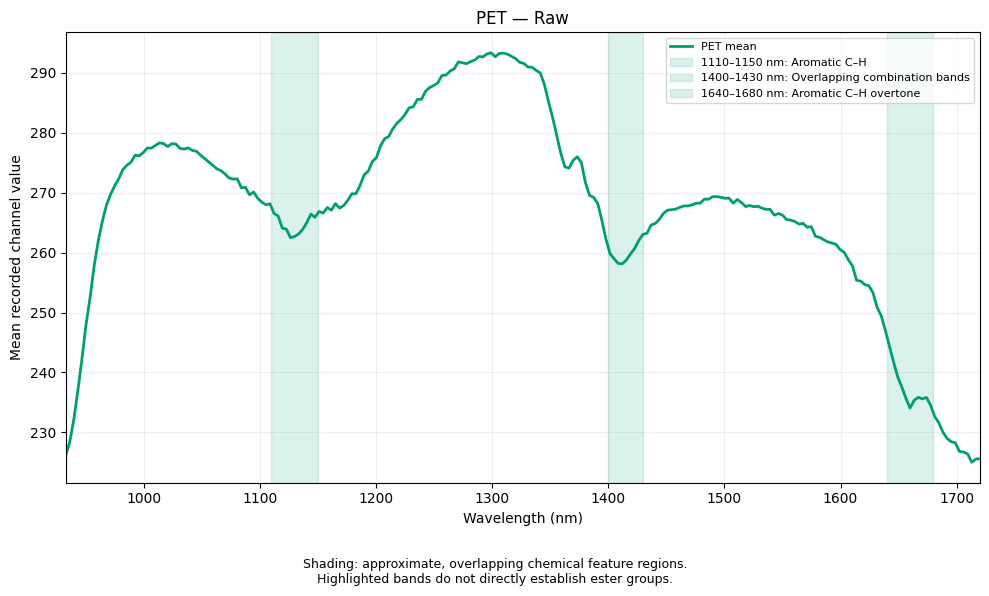

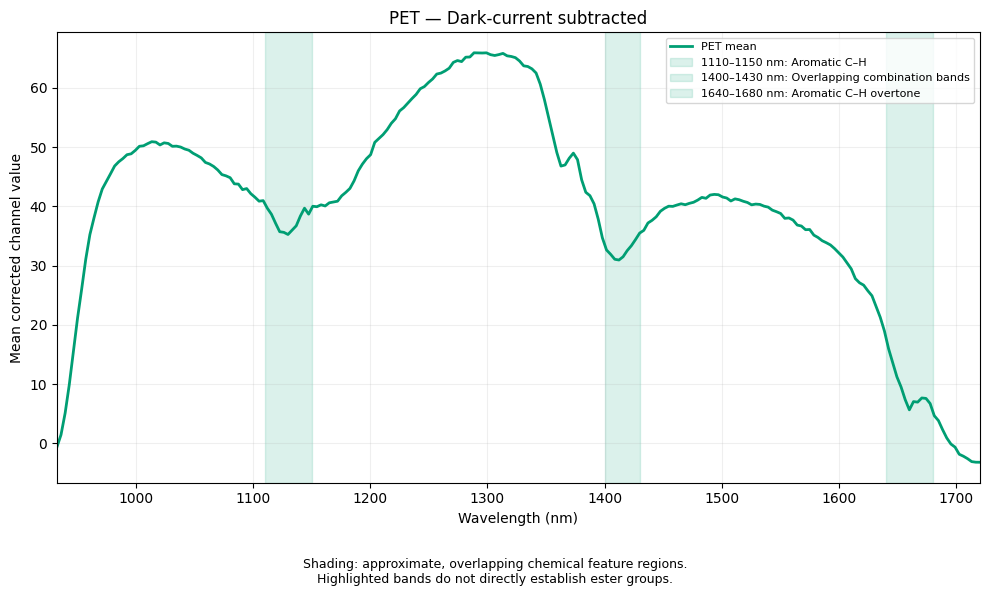

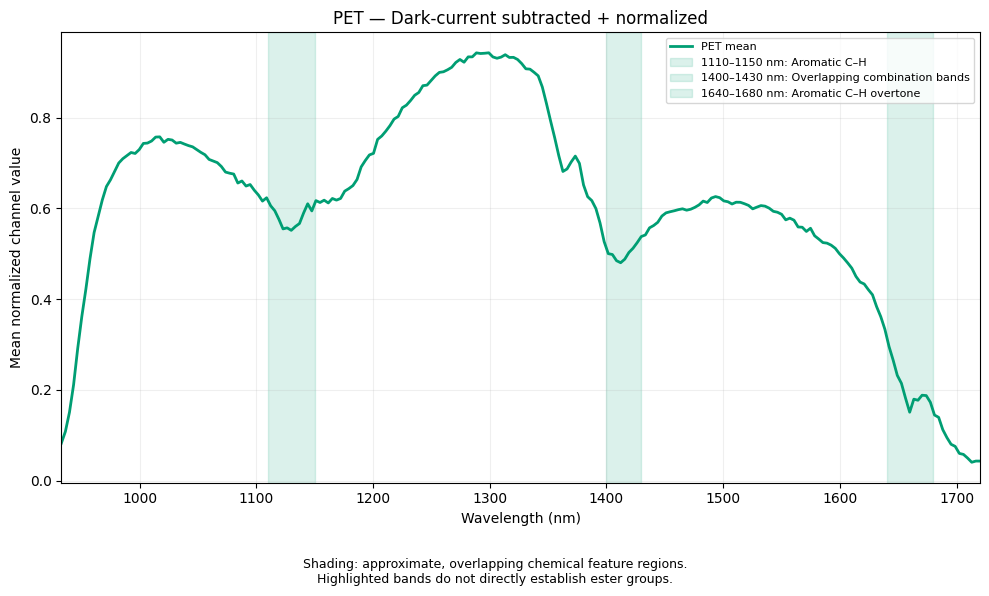

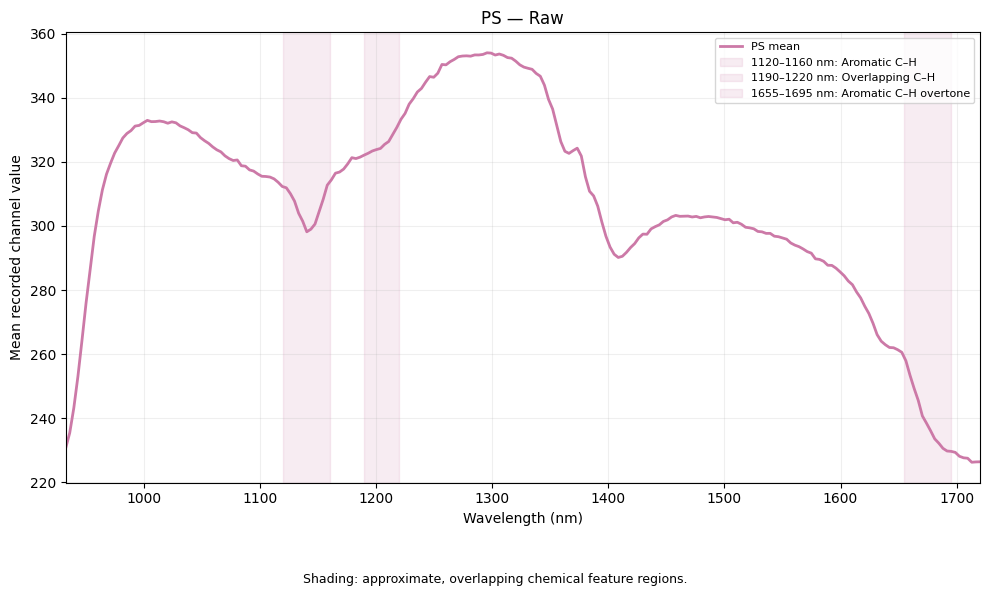

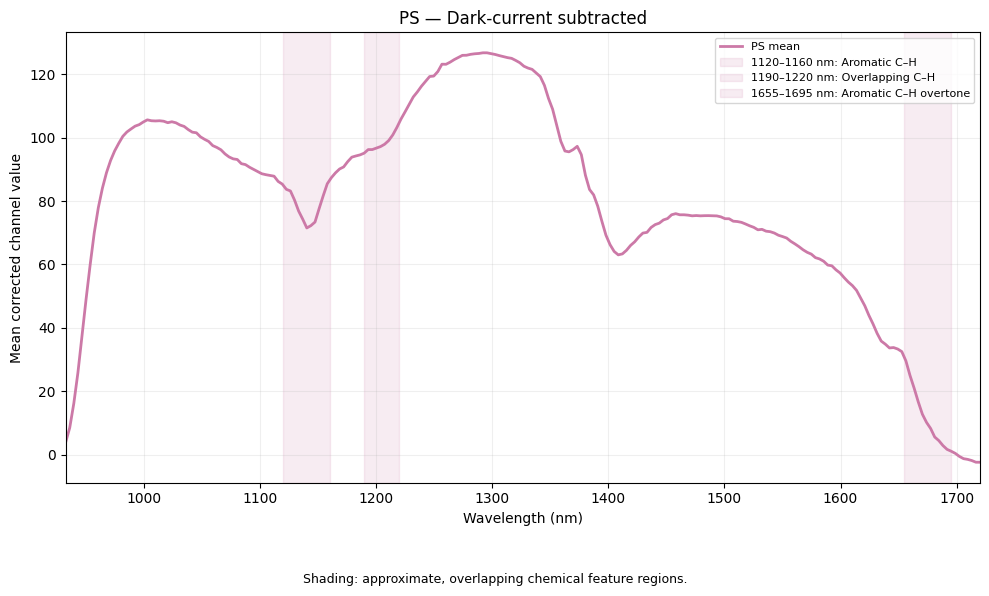

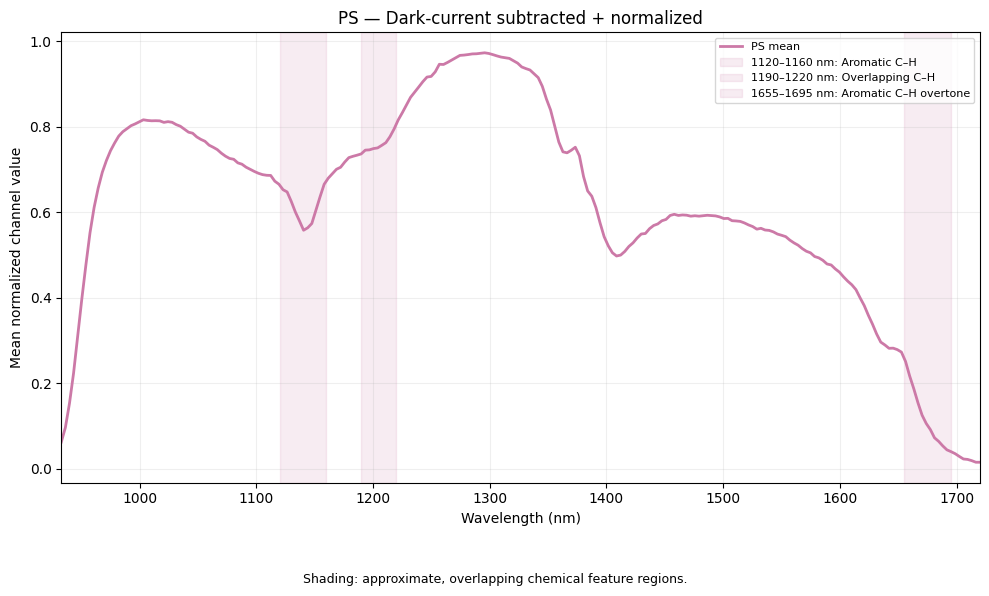

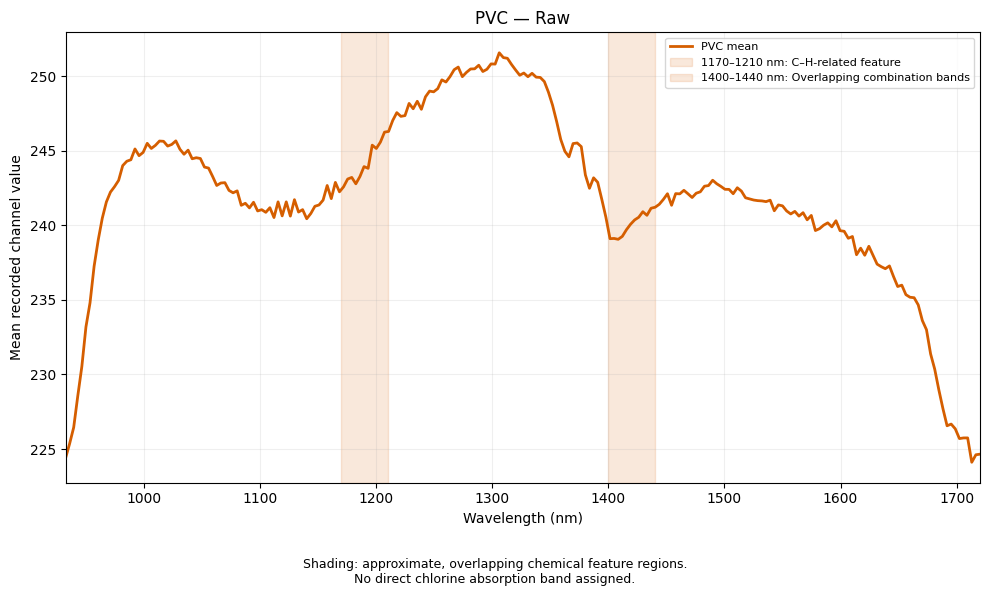

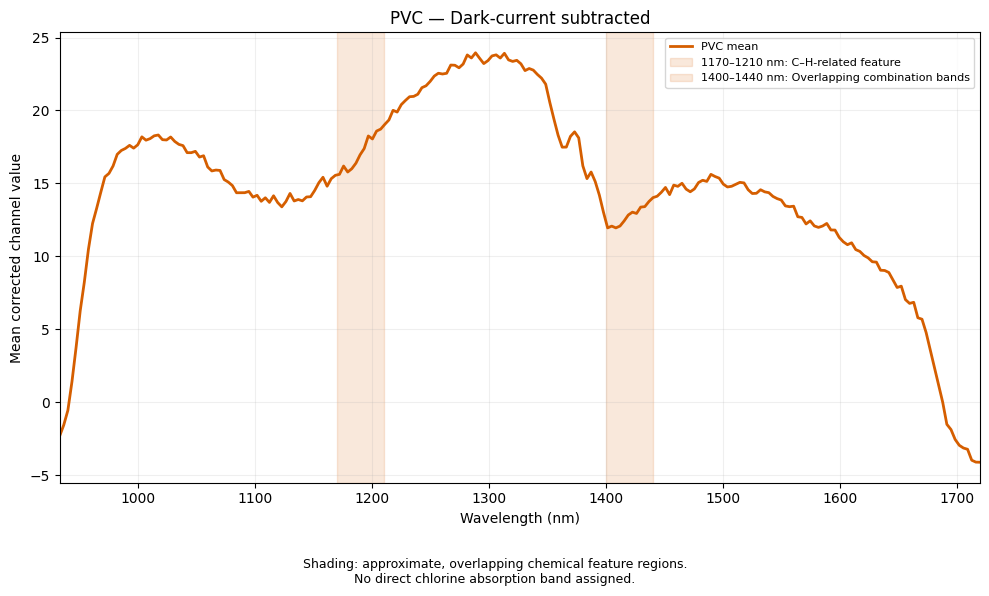

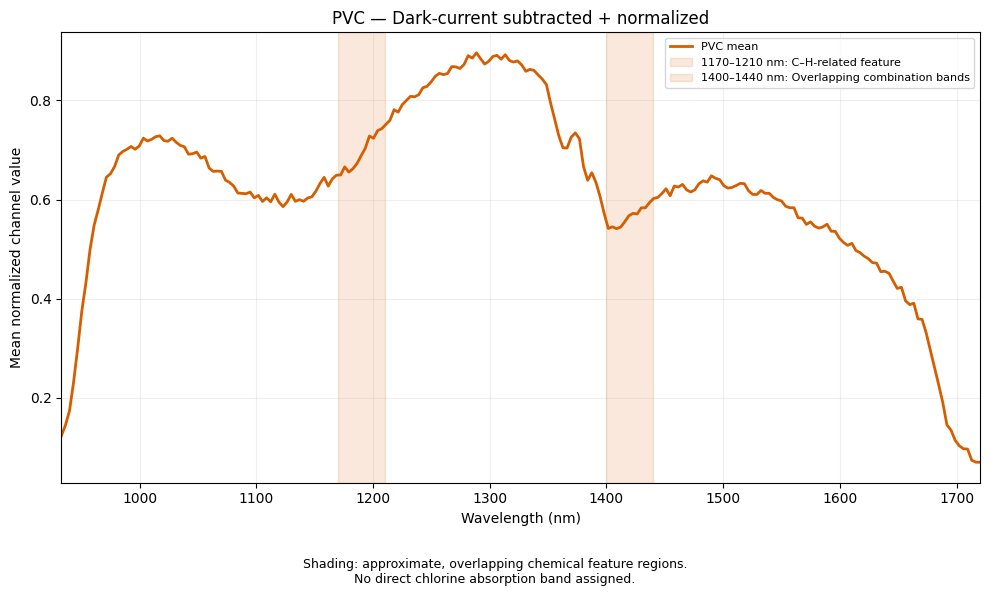

Saved 15 images to: /Users/williamronan/PythonTools/HyperspectralPVCSort/images/spectral_patterns


In [13]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Compare category-average spectra before and after dark-current correction
# and normalization, highlighting approximate chemical feature regions.

output_dir = Path("images") / "spectral_patterns"
output_dir.mkdir(parents=True, exist_ok=True)

channel_cols = [f"ch.{i}" for i in range(1, 225)]

class_names = {
    1: "PE",
    2: "PP",
    3: "PET",
    4: "PS",
    5: "PVC"
}

class_colours = {
    1: "#0072B2",
    2: "#E69F00",
    3: "#009E73",
    4: "#CC79A7",
    5: "#D55E00"
}

# Approximate, overlapping literature regions—not exclusive identifiers.
feature_regions = {
    1: [
        (1195, 1225, "CH₂-related C–H"),
        (1410, 1450, "C–H combinations")
    ],
    2: [
        (1140, 1210, "CH₃-related / overlapping C–H"),
        (1380, 1420, "C–H combinations")
    ],
    3: [
        (1110, 1150, "Aromatic C–H"),
        (1400, 1430, "Overlapping combination bands"),
        (1640, 1680, "Aromatic C–H overtone")
    ],
    4: [
        (1120, 1160, "Aromatic C–H"),
        (1190, 1220, "Overlapping C–H"),
        (1655, 1695, "Aromatic C–H overtone")
    ],
    5: [
        (1170, 1210, "C–H-related feature"),
        (1400, 1440, "Overlapping combination bands")
    ]
}

# Read wavelengths in the same order as ch.1–ch.224.
wavelength_nm = (
    wavelength.set_index("channel")
    .loc[range(1, 225), "wavelength"]
    .to_numpy(dtype=float)
)

# Average the 640 dark-reference rows separately for each channel.
# This is a global reference, not a detector-position-specific correction.
dark_values = darkcurrent[channel_cols].apply(
    pd.to_numeric, errors="raise"
).to_numpy(dtype=float)

raw = trainSet[channel_cols].apply(
    pd.to_numeric, errors="raise"
).to_numpy(dtype=float)

for name, values in [
    ("Wavelengths", wavelength_nm),
    ("Dark current", dark_values),
    ("Training spectra", raw)
]:
    if not np.isfinite(values).all():
        raise ValueError(f"{name} contains missing or non-finite values.")

if not (np.diff(wavelength_nm) > 0).all():
    raise ValueError("Wavelengths must increase in channel order.")

dark_vector = dark_values.mean(axis=0)
corrected = raw - dark_vector

# Scale each corrected spectrum independently to [0, 1].
row_min = corrected.min(axis=1, keepdims=True)
row_range = np.ptp(corrected, axis=1, keepdims=True)
valid_normalization = row_range[:, 0] > 0

normalized = np.full_like(corrected, np.nan)
normalized[valid_normalization] = (
    corrected[valid_normalization] - row_min[valid_normalization]
) / row_range[valid_normalization]

labels = pd.to_numeric(
    trainSet["class_id"], errors="raise"
).to_numpy()

if not np.isin(labels, list(class_names)).all():
    raise ValueError("Class labels must be integers from 1 to 5.")

versions = [
    (
        "raw",
        raw,
        "Raw",
        "Mean recorded channel value"
    ),
    (
        "dark_corrected",
        corrected,
        "Dark-current subtracted",
        "Mean corrected channel value"
    ),
    (
        "dark_corrected_normalized",
        normalized,
        "Dark-current subtracted + normalized",
        "Mean normalized channel value"
    )
]

print(
    f"Wavelength range: {wavelength_nm.min():.2f}–"
    f"{wavelength_nm.max():.2f} nm"
)
print(
    "Constant spectra excluded from normalized averages: "
    f"{(~valid_normalization).sum():,}"
)

saved_count = 0

for class_id, plastic in class_names.items():
    category_mask = labels == class_id

    if not category_mask.any():
        raise ValueError(f"No measurements found for {plastic}.")

    for filename_tag, spectra, title_tag, ylabel in versions:
        selection = category_mask.copy()

        if filename_tag == "dark_corrected_normalized":
            selection &= valid_normalization

        if not selection.any():
            raise ValueError(
                f"No valid spectra for {plastic}: {title_tag}."
            )

        # Every measurement row contributes equally to its category mean.
        mean_spectrum = spectra[selection].mean(axis=0)

        fig, ax = plt.subplots(figsize=(10, 6))

        ax.plot(
            wavelength_nm,
            mean_spectrum,
            color=class_colours[class_id],
            linewidth=2,
            label=f"{plastic} mean"
        )

        for lower, upper, feature in feature_regions[class_id]:
            ax.axvspan(
                lower,
                upper,
                color=class_colours[class_id],
                alpha=0.14,
                label=f"{lower}–{upper} nm: {feature}"
            )

        ax.set(
            xlabel="Wavelength (nm)",
            ylabel=ylabel,
            title=f"{plastic} — {title_tag}",
            xlim=(wavelength_nm.min(), wavelength_nm.max())
        )

        ax.grid(alpha=0.2)
        ax.legend(loc="best", fontsize=8)

        note = (
            "Shading: approximate, overlapping chemical feature regions."
        )

        if plastic == "PVC":
            note += "\nNo direct chlorine absorption band assigned."
        elif plastic == "PET":
            note += (
                "\nHighlighted bands do not directly establish ester groups."
            )

        fig.text(
            0.5, 0.02,
            note,
            ha="center",
            fontsize=9
        )
        fig.tight_layout(rect=(0, 0.09, 1, 1))

        output_path = output_dir / f"{plastic}_{filename_tag}.png"
        fig.savefig(output_path, dpi=300, bbox_inches="tight")

        plt.show()
        plt.close(fig)
        saved_count += 1

print(f"Saved {saved_count} images to: {output_dir.resolve()}")

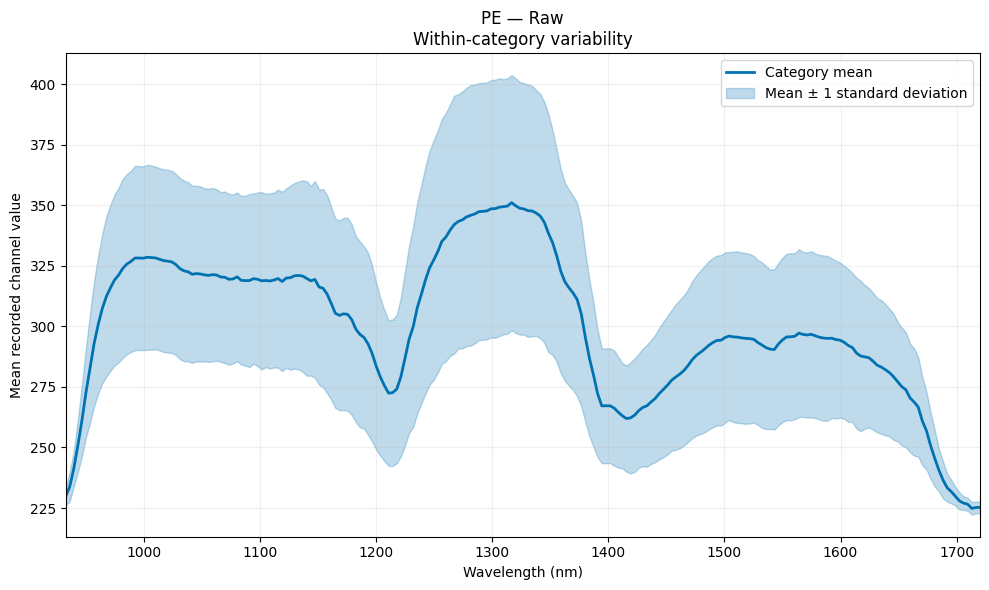

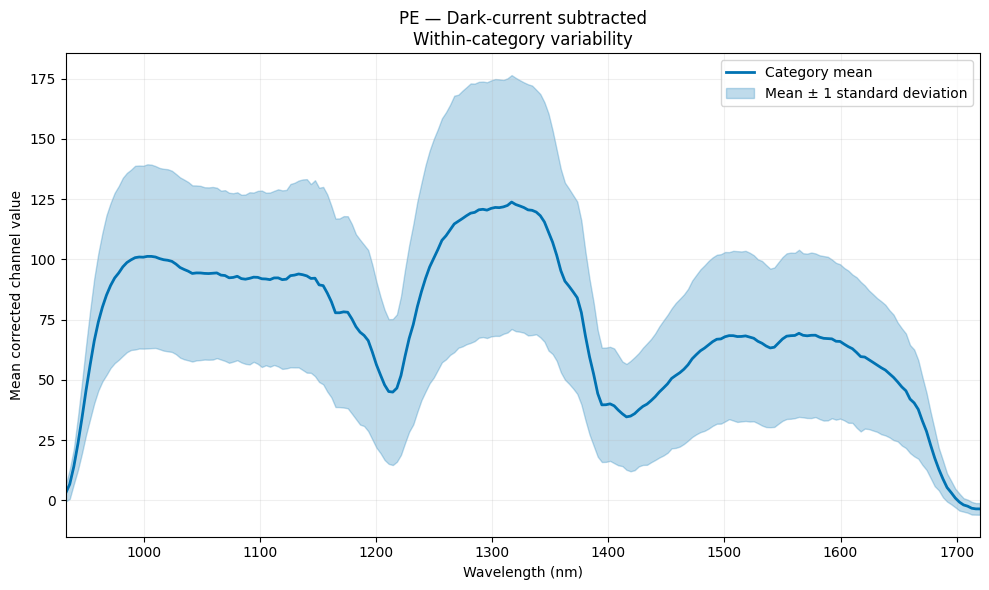

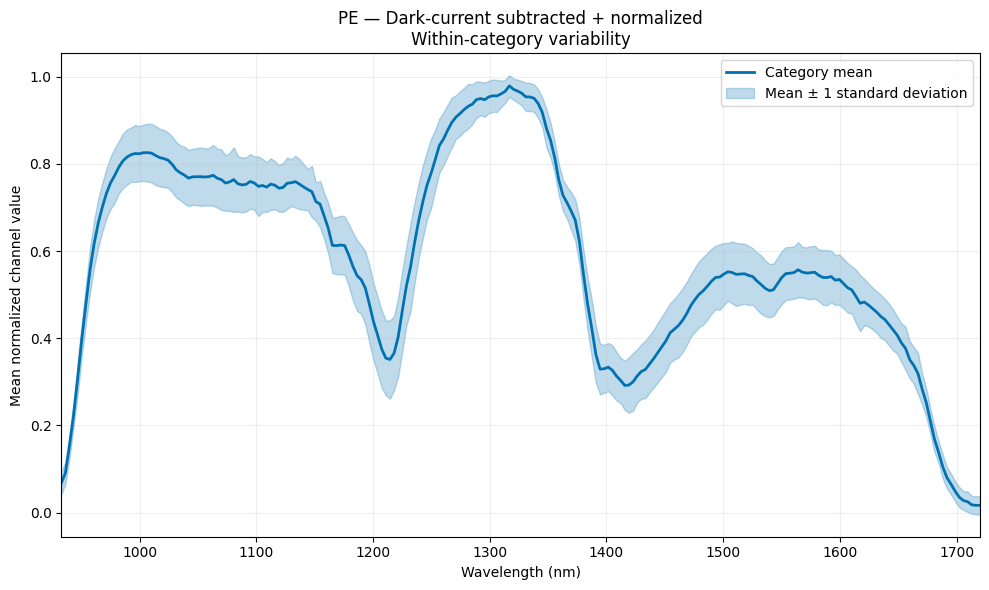

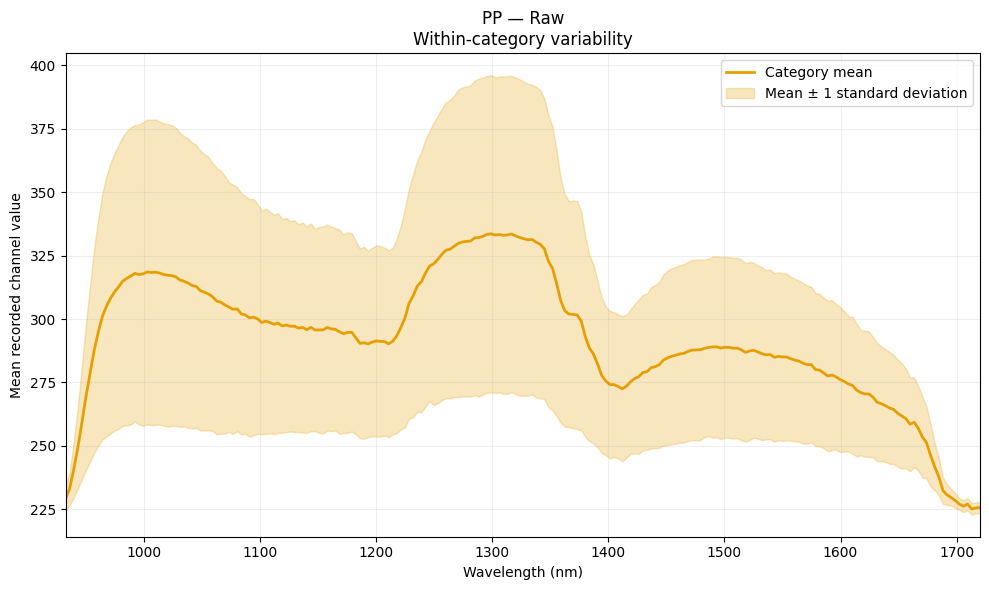

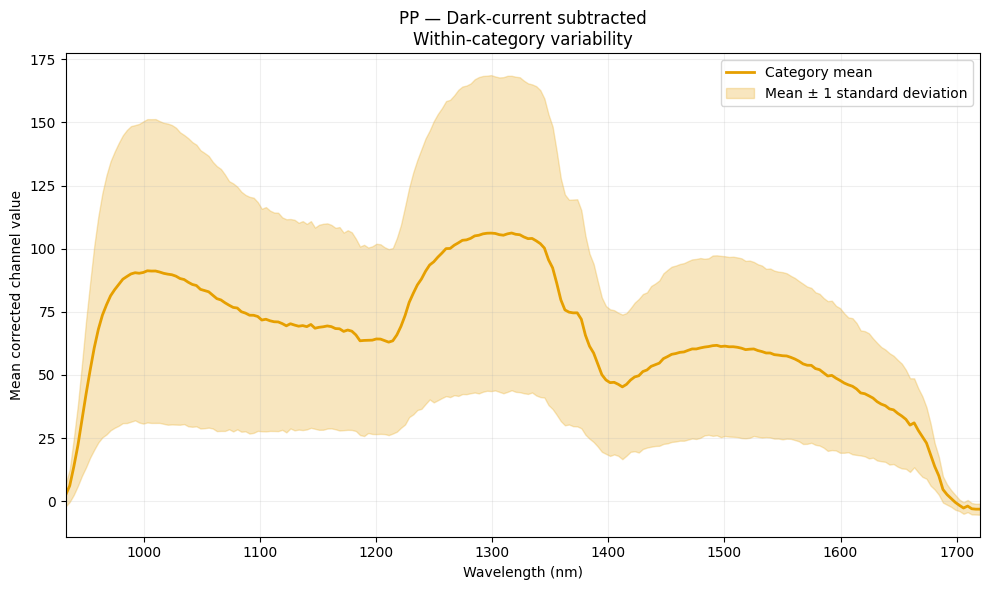

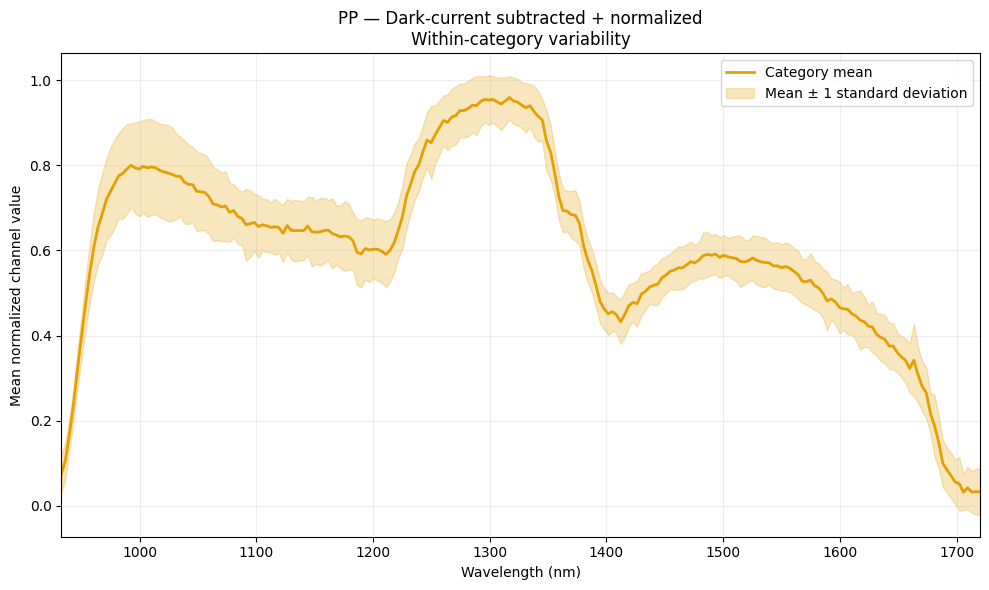

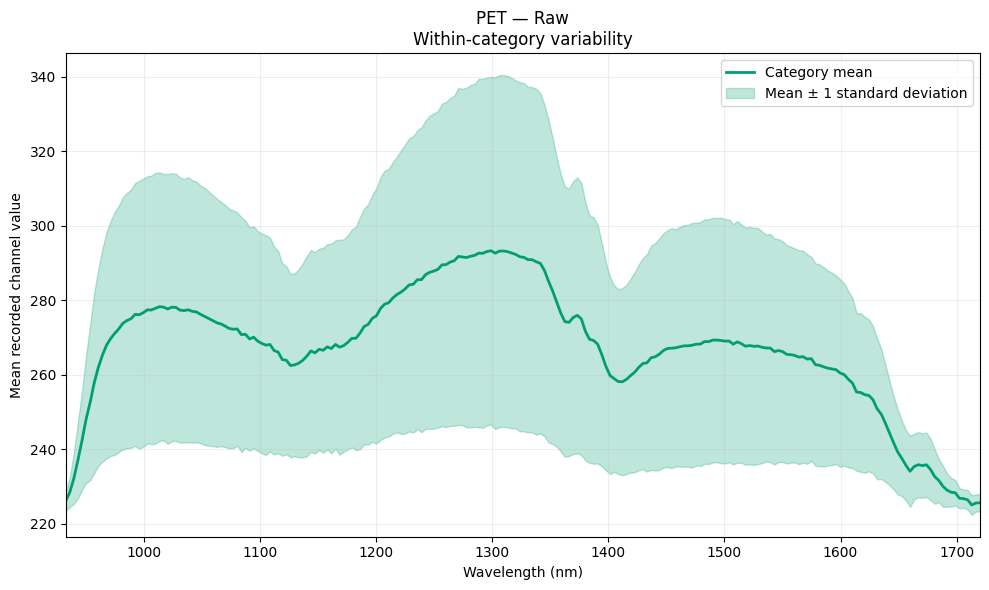

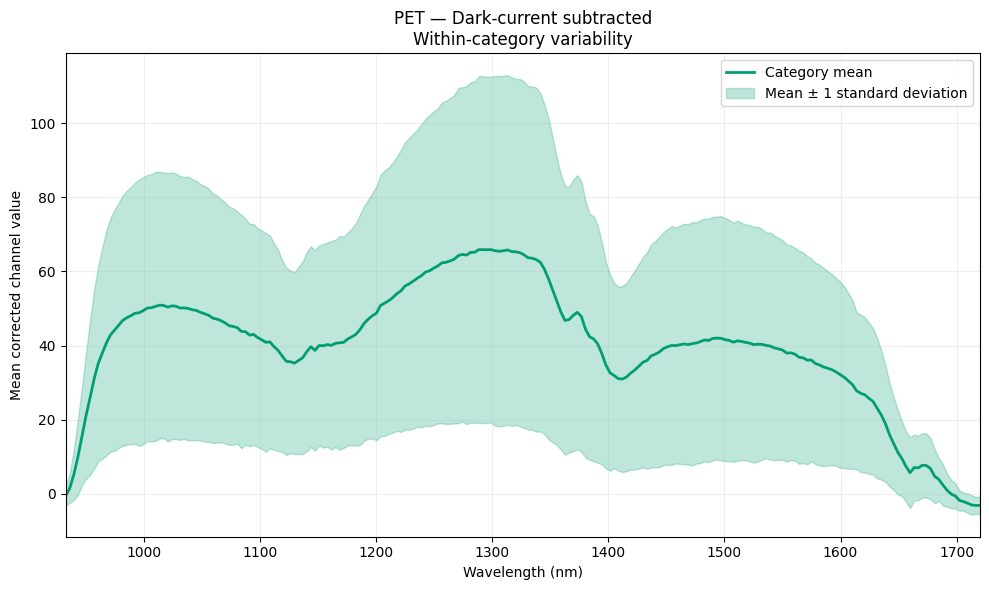

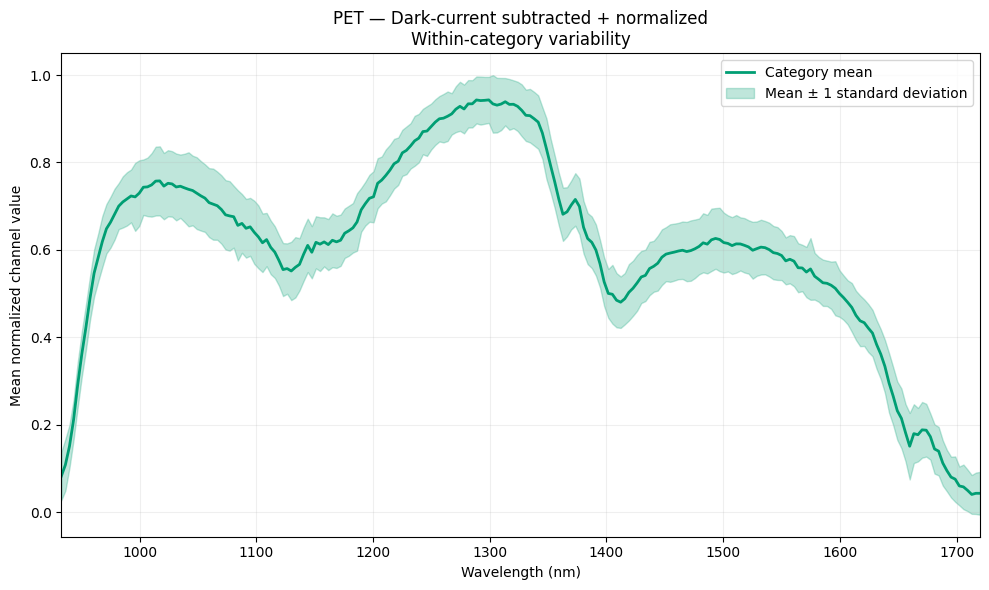

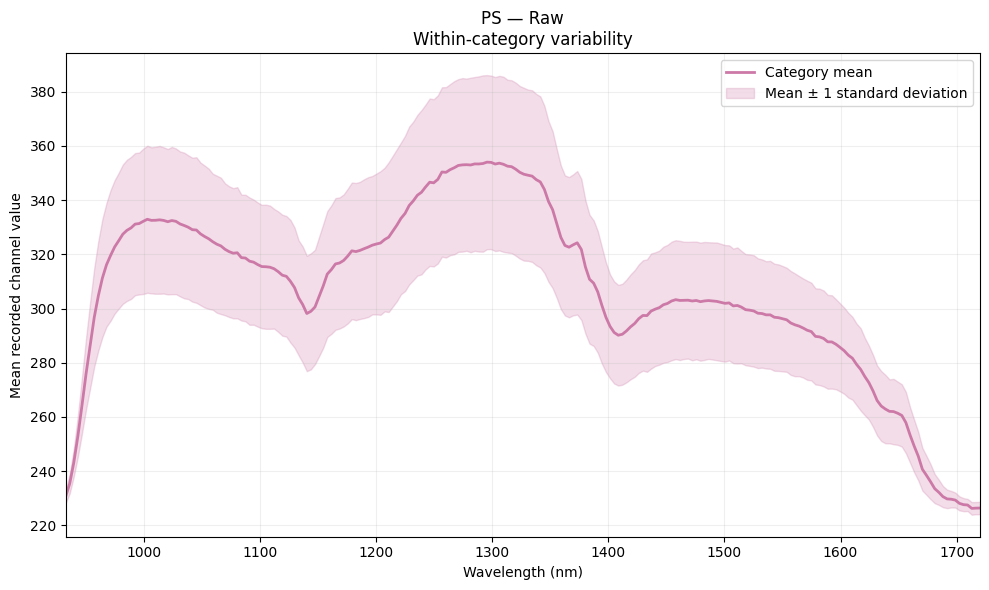

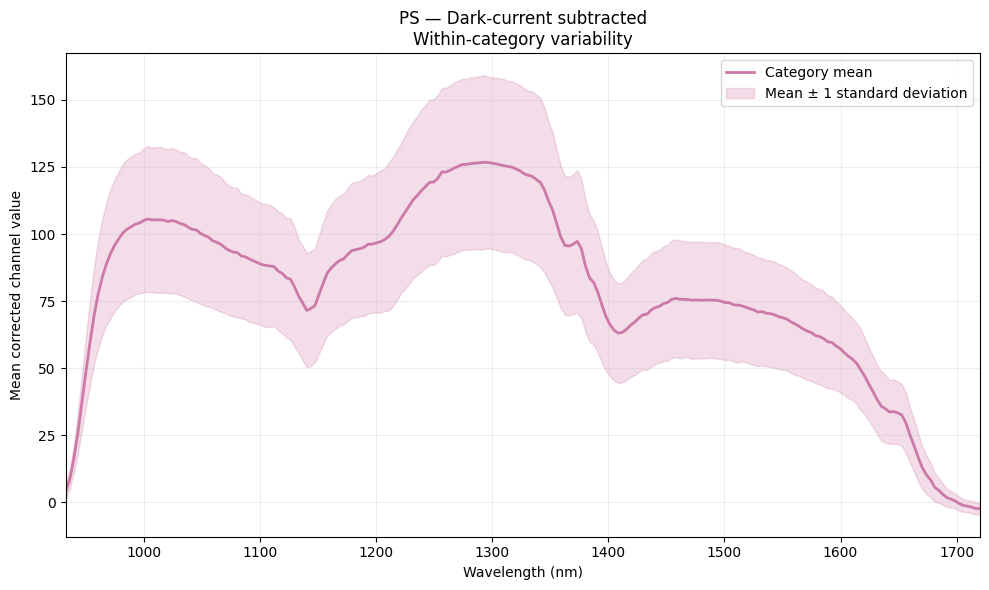

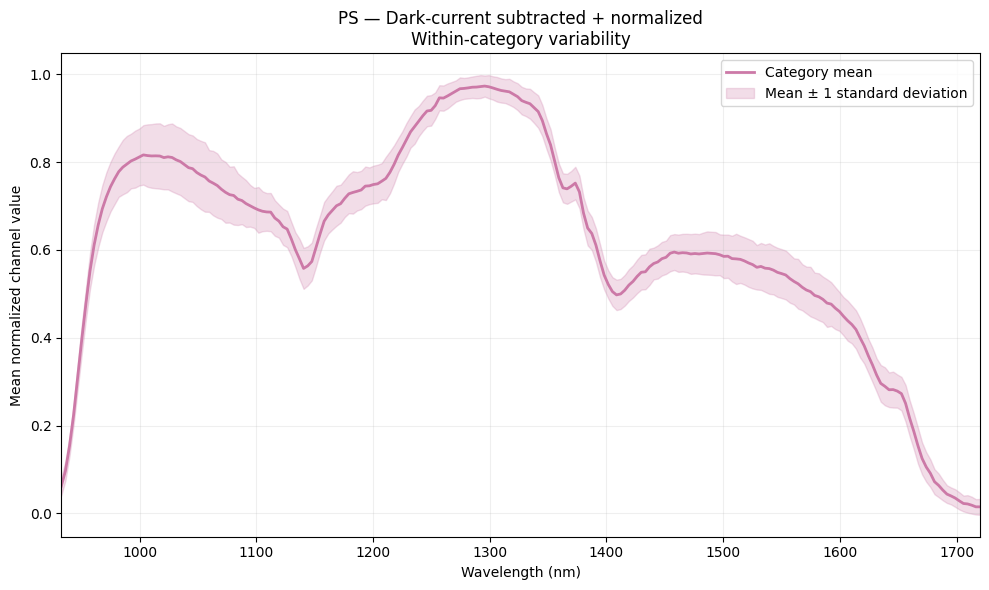

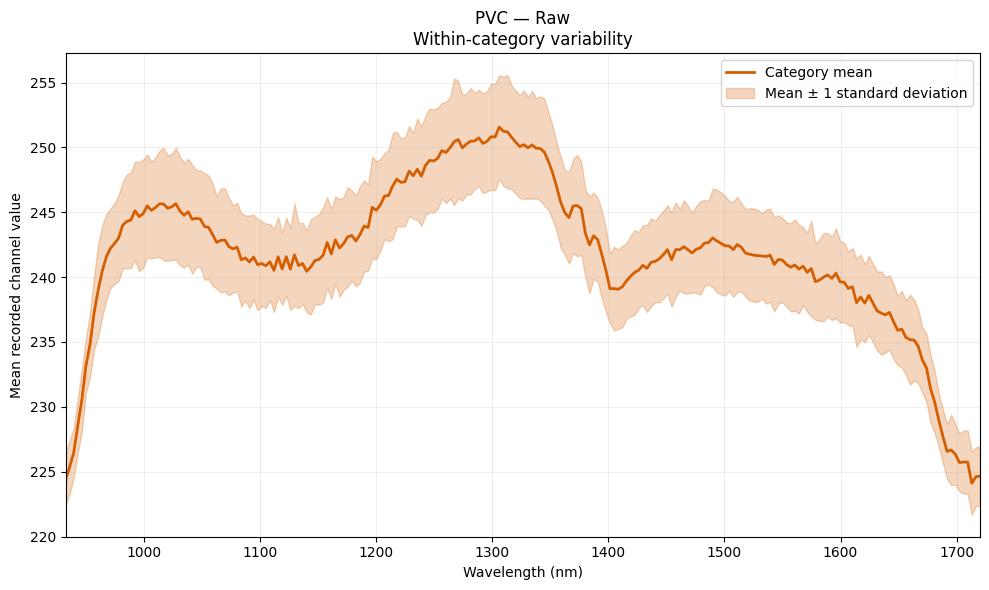

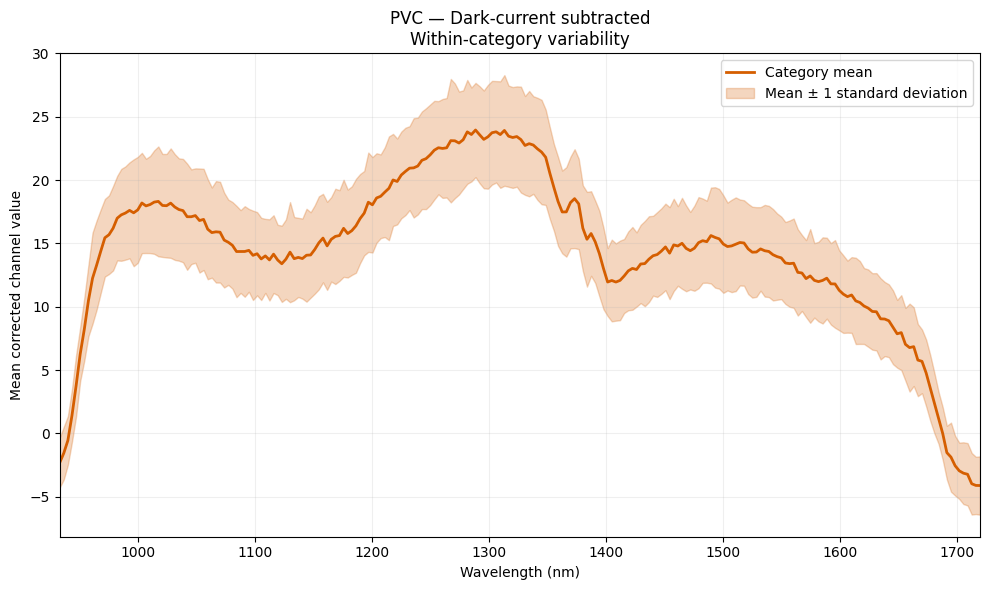

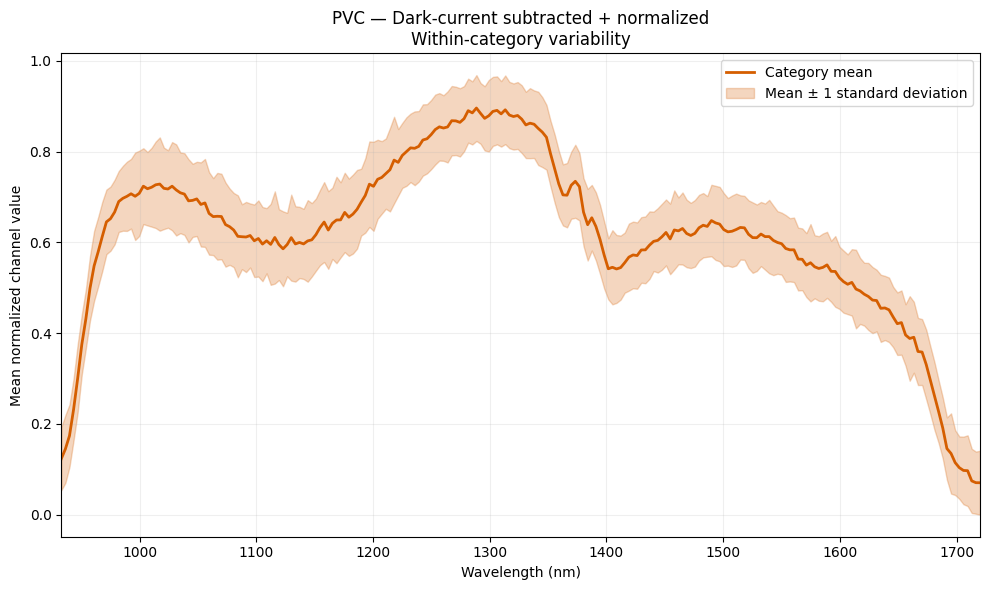

,plastic,processing,rows,mean_channel_variance,mean_channel_std,max_channel_std,wavelength_of_max_std_nm
0,PE,raw,10235,1273.3846,33.7869,53.8185,1281.49
1,PE,dark_corrected,10235,1273.3846,33.7869,53.8185,1281.49
2,PE,dark_corrected_normalized,10235,0.0036,0.0573,0.1011,1232.10
3,PP,raw,9877,1790.2562,39.3214,62.6306,1288.55
4,PP,dark_corrected,9877,1790.2562,39.3214,62.6306,1288.55
5,PP,dark_corrected_normalized,9877,0.0045,0.0645,0.1147,1006.67
6,PET,raw,9869,1002.9811,29.7251,47.2849,1306.19
7,PET,dark_corrected,9869,1002.9811,29.7251,47.2849,1306.19
8,PET,dark_corrected_normalized,9869,0.0038,0.0608,0.0847,1041.86
9,PS,raw,9963,525.0360,21.6467,32.5137,1292.08


Saved to: /Users/williamronan/PythonTools/HyperspectralPVCSort/images/spectral_patterns_with_variance


In [15]:
# Assess how representative each category mean is of individual spectra.
# Shading shows mean ± one standard deviation, not a confidence interval.

variability_dir = Path("images") / "spectral_patterns_with_variance"
variability_dir.mkdir(parents=True, exist_ok=True)

variance_tables = {}
summary_rows = []

for class_id, plastic in class_names.items():
    category_mask = labels == class_id

    for filename_tag, spectra, title_tag, ylabel in versions:
        selection = category_mask.copy()

        if filename_tag == "dark_corrected_normalized":
            selection &= valid_normalization

        category_spectra = spectra[selection]

        if len(category_spectra) < 2:
            raise ValueError(
                f"At least two valid spectra are needed for {plastic}."
            )

        mean_spectrum = category_spectra.mean(axis=0)
        variance = category_spectra.var(axis=0, ddof=1)
        std = np.sqrt(variance)

        # Keep channel-wise statistics available for later analysis.
        statistics = pd.DataFrame({
            "channel": channel_cols,
            "wavelength_nm": wavelength_nm,
            "mean": mean_spectrum,
            "variance": variance,
            "std": std
        })

        variance_tables[(plastic, filename_tag)] = statistics
        statistics.to_csv(
            variability_dir / f"{plastic}_{filename_tag}_statistics.csv",
            index=False
        )

        summary_rows.append({
            "plastic": plastic,
            "processing": filename_tag,
            "rows": len(category_spectra),
            "mean_channel_variance": variance.mean(),
            "mean_channel_std": std.mean(),
            "max_channel_std": std.max(),
            "wavelength_of_max_std_nm": wavelength_nm[std.argmax()]
        })

        fig, ax = plt.subplots(figsize=(10, 6))
        colour = class_colours[class_id]

        ax.plot(
            wavelength_nm,
            mean_spectrum,
            color=colour,
            linewidth=2,
            label="Category mean"
        )

        ax.fill_between(
            wavelength_nm,
            mean_spectrum - std,
            mean_spectrum + std,
            color=colour,
            alpha=0.25,
            label="Mean ± 1 standard deviation"
        )

        ax.set(
            xlabel="Wavelength (nm)",
            ylabel=ylabel,
            title=f"{plastic} — {title_tag}\nWithin-category variability",
            xlim=(wavelength_nm.min(), wavelength_nm.max())
        )
        ax.grid(alpha=0.2)
        ax.legend()
        fig.tight_layout()

        fig.savefig(
            variability_dir / f"{plastic}_{filename_tag}_variability.png",
            dpi=300,
            bbox_inches="tight"
        )

        plt.show()
        plt.close(fig)

variance_summary = pd.DataFrame(summary_rows)
variance_summary.to_csv(
    variability_dir / "variance_summary.csv",
    index=False
)

display(variance_summary.round(4))
print(f"Saved to: {variability_dir.resolve()}")

Saved: /Users/williamronan/PythonTools/HyperspectralPVCSort/images/average_spectra_overlay.png
Saved: /Users/williamronan/PythonTools/HyperspectralPVCSort/images/average_spectra_overlay_with_variance.png


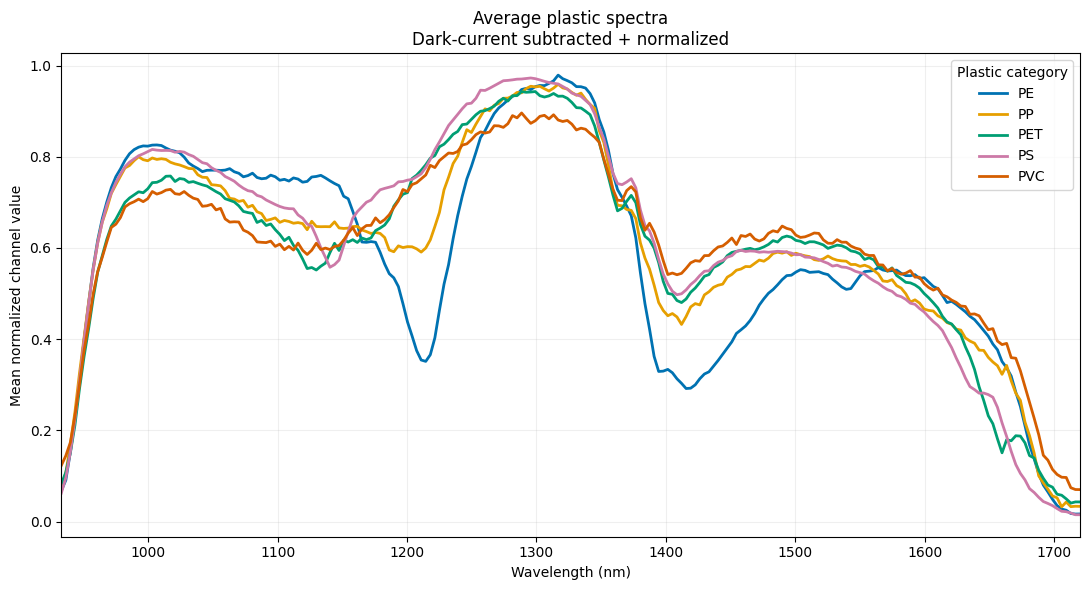

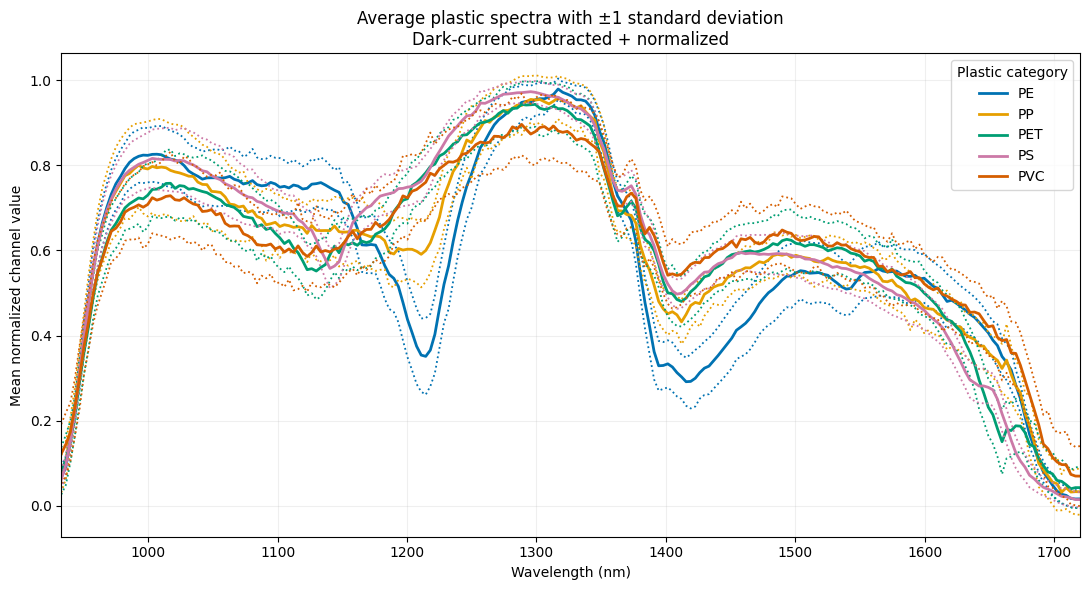

In [16]:
# Overlay category means to compare spectral shapes and their variability.
image_dir = Path("images")
image_dir.mkdir(parents=True, exist_ok=True)

fig_mean, ax_mean = plt.subplots(figsize=(11, 6))
fig_std, ax_std = plt.subplots(figsize=(11, 6))

for class_id, plastic in class_names.items():
    selection = (labels == class_id) & valid_normalization
    spectra = normalized[selection]

    mean_spectrum = spectra.mean(axis=0)
    std = spectra.std(axis=0, ddof=1)
    colour = class_colours[class_id]

    ax_mean.plot(
        wavelength_nm, mean_spectrum,
        color=colour, linewidth=2, label=plastic
    )

    ax_std.plot(
        wavelength_nm, mean_spectrum,
        color=colour, linewidth=2, label=plastic
    )
    ax_std.plot(
        wavelength_nm, mean_spectrum - std,
        color=colour, linestyle=":", linewidth=1.3
    )
    ax_std.plot(
        wavelength_nm, mean_spectrum + std,
        color=colour, linestyle=":", linewidth=1.3
    )

for fig, ax, title, filename in [
    (
        fig_mean, ax_mean,
        "Average plastic spectra",
        "average_spectra_overlay.png"
    ),
    (
        fig_std, ax_std,
        "Average plastic spectra with ±1 standard deviation",
        "average_spectra_overlay_with_variance.png"
    )
]:
    ax.set(
        xlabel="Wavelength (nm)",
        ylabel="Mean normalized channel value",
        title=f"{title}\nDark-current subtracted + normalized",
        xlim=(wavelength_nm.min(), wavelength_nm.max())
    )
    ax.grid(alpha=0.2)
    ax.legend(title="Plastic category")
    fig.tight_layout()

    output_path = image_dir / filename
    fig.savefig(output_path, dpi=300, bbox_inches="tight")
    print(f"Saved: {output_path.resolve()}")

plt.show()
plt.close(fig_mean)
plt.close(fig_std)

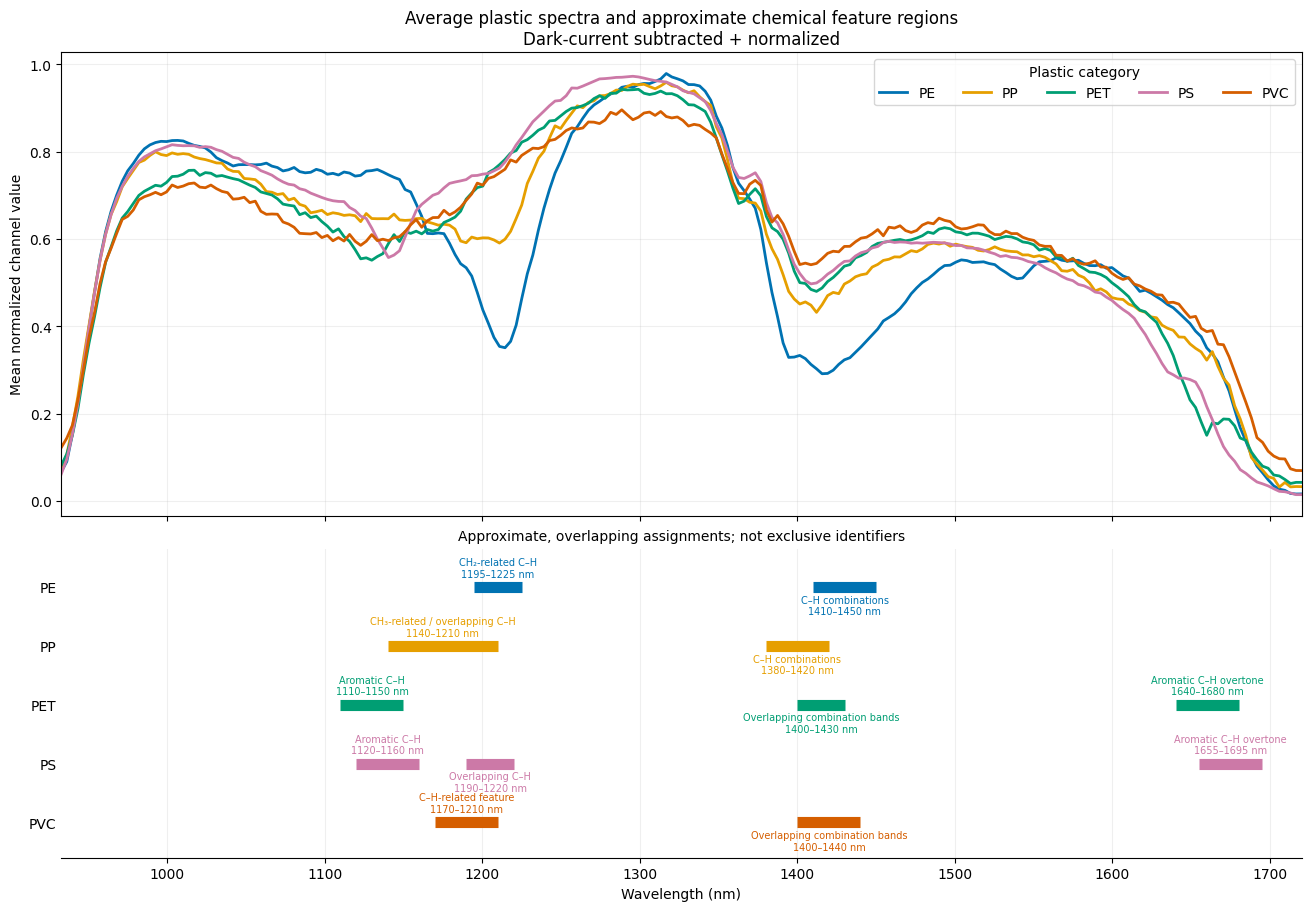

Saved: /Users/williamronan/PythonTools/HyperspectralPVCSort/images/average_spectra_overlay_with_features.png


In [17]:
# Compare normalized category means, with chemical feature regions shown
# on separate annotation rows to keep overlapping regions readable.

fig, (ax, feature_ax) = plt.subplots(
    2, 1,
    figsize=(13, 9),
    sharex=True,
    gridspec_kw={"height_ratios": [3, 2]},
    constrained_layout=True
)

# Category-average spectra, without variance.
for class_id, plastic in class_names.items():
    selection = (labels == class_id) & valid_normalization

    ax.plot(
        wavelength_nm,
        normalized[selection].mean(axis=0),
        color=class_colours[class_id],
        linewidth=2,
        label=plastic
    )

ax.set_title(
    "Average plastic spectra and approximate chemical feature regions\n"
    "Dark-current subtracted + normalized"
)
ax.set_ylabel("Mean normalized channel value")
ax.grid(alpha=0.2)
ax.legend(title="Plastic category", ncol=5, loc="best")

# Give each category its own row; stagger labels within each row.
for row, (class_id, plastic) in enumerate(class_names.items()):
    colour = class_colours[class_id]

    for feature_index, (lower, upper, feature) in enumerate(
        feature_regions[class_id]
    ):
        centre = (lower + upper) / 2

        feature_ax.plot(
            [lower, upper], [row, row],
            color=colour,
            linewidth=8,
            solid_capstyle="butt"
        )

        # Alternating label heights reduce collisions between nearby bands.
        offset = -0.32 if feature_index % 2 == 0 else 0.32

        feature_ax.text(
            centre,
            row + offset,
            f"{feature}\n{lower}–{upper} nm",
            ha="center",
            va="center",
            fontsize=7,
            color=colour
        )

feature_ax.set_yticks(range(len(class_names)))
feature_ax.set_yticklabels(class_names.values())
feature_ax.set_ylim(len(class_names) - 0.4, -0.65)
feature_ax.set_xlim(wavelength_nm.min(), wavelength_nm.max())
feature_ax.set_xlabel("Wavelength (nm)")
feature_ax.set_title(
    "Approximate, overlapping assignments; not exclusive identifiers",
    fontsize=10
)
feature_ax.grid(axis="x", alpha=0.2)
feature_ax.tick_params(axis="y", length=0)

for spine in ["top", "right", "left"]:
    feature_ax.spines[spine].set_visible(False)

image_dir = Path("images")
image_dir.mkdir(parents=True, exist_ok=True)
output_path = image_dir / "average_spectra_overlay_with_features.png"

fig.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

print(f"Saved: {output_path.resolve()}")

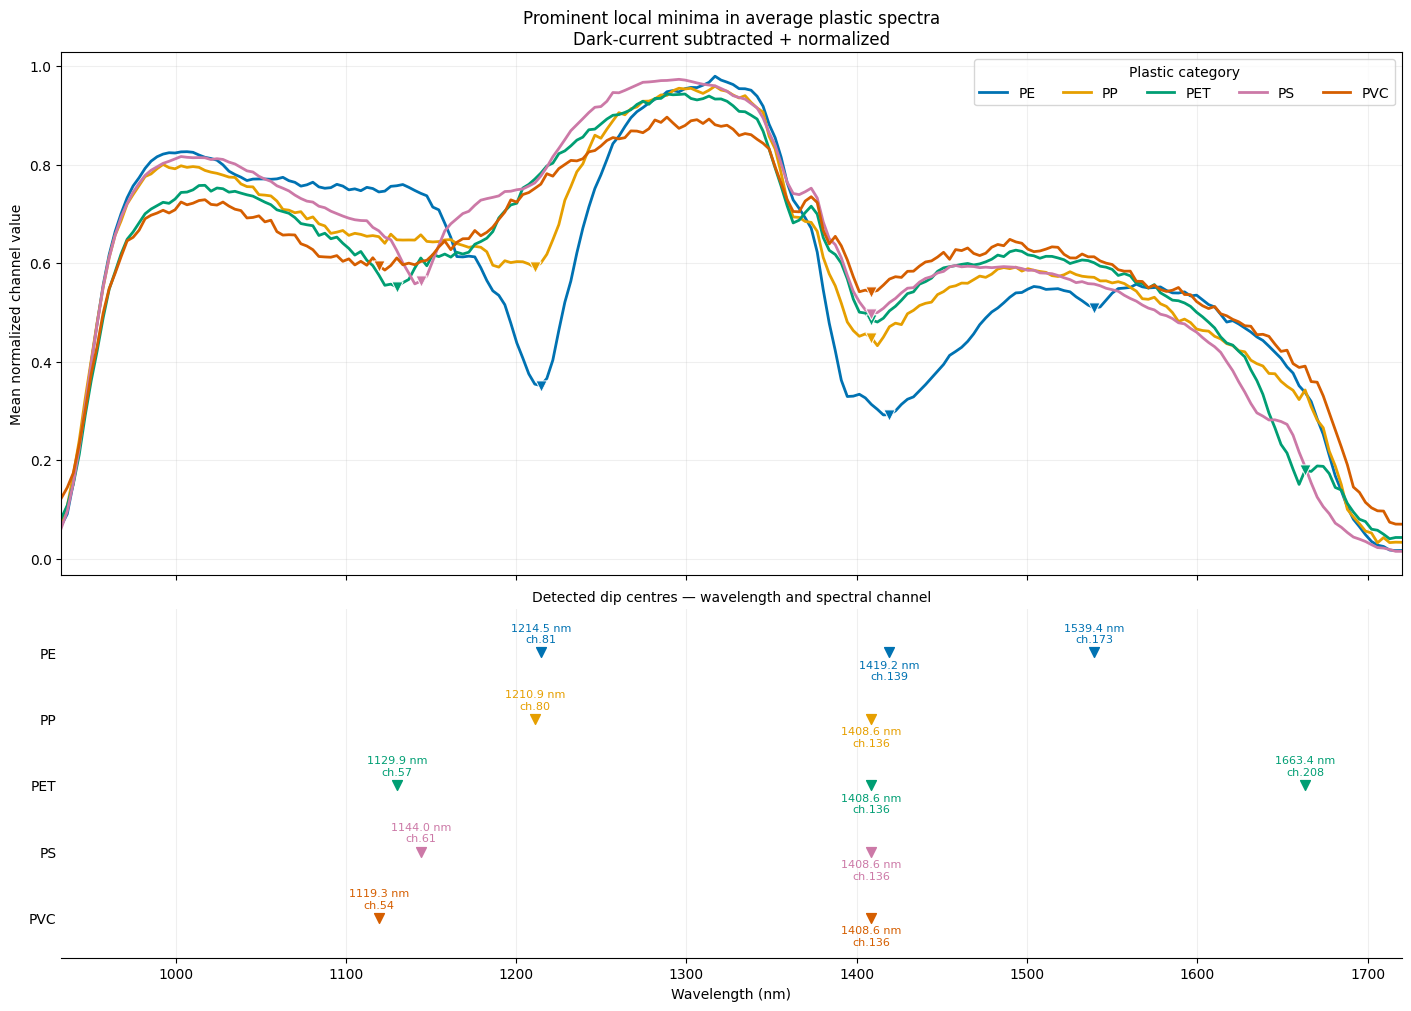

,plastic,channel,wavelength_nm,mean_normalized_value
0,PE,81,1214.47,0.351
1,PE,139,1419.20,0.292
2,PE,173,1539.43,0.509
3,PP,80,1210.94,0.591
4,PP,136,1408.60,0.449
5,PET,57,1129.88,0.552
6,PET,136,1408.60,0.485
7,PET,208,1663.36,0.179
8,PS,61,1143.98,0.563
9,PS,136,1408.60,0.497


Saved: /Users/williamronan/PythonTools/HyperspectralPVCSort/images/average_spectra_local_minima.png


In [18]:
from scipy.signal import find_peaks, savgol_filter

# Detect prominent local minima in category-average normalized spectra.
# Light smoothing reduces noise; these are detected dips, not chemical assignments.

MIN_PROMINENCE = 0.02   # Increase to retain only stronger dips.
MIN_DISTANCE = 8        # Minimum separation in channels.
MAX_DIPS = 5           # Maximum labelled dips per category.

fig, (ax, band_ax) = plt.subplots(
    2, 1,
    figsize=(14, 10),
    sharex=True,
    gridspec_kw={"height_ratios": [3, 2]},
    constrained_layout=True
)

dip_records = []

for row, (class_id, plastic) in enumerate(class_names.items()):
    selection = (labels == class_id) & valid_normalization
    mean_spectrum = normalized[selection].mean(axis=0)
    colour = class_colours[class_id]

    # Smooth only for detection; plot the original mean spectrum.
    smoothed = savgol_filter(mean_spectrum, window_length=7, polyorder=2)

    # Minima become peaks when the spectrum is inverted.
    minima, properties = find_peaks(
        -smoothed,
        prominence=MIN_PROMINENCE,
        distance=MIN_DISTANCE
    )

    # Retain the most prominent dips, then order by wavelength.
    strongest = np.argsort(properties["prominences"])[::-1][:MAX_DIPS]
    selected = np.sort(minima[strongest])

    ax.plot(
        wavelength_nm, mean_spectrum,
        color=colour, linewidth=2, label=plastic
    )
    ax.scatter(
        wavelength_nm[selected],
        mean_spectrum[selected],
        color=colour,
        marker="v",
        s=65,
        edgecolors="white",
        linewidths=0.7,
        zorder=5
    )

    # Separate annotation row for each category.
    for number, index in enumerate(selected):
        wave = wavelength_nm[index]
        channel = index + 1

        band_ax.scatter(
            wave, row,
            color=colour, marker="v", s=50
        )

        offset = -0.28 if number % 2 == 0 else 0.28
        band_ax.text(
            wave, row + offset,
            f"{wave:.1f} nm\nch.{channel}",
            ha="center", va="center",
            fontsize=8, color=colour
        )

        dip_records.append({
            "plastic": plastic,
            "channel": channel,
            "wavelength_nm": wave,
            "mean_normalized_value": mean_spectrum[index]
        })

    if len(selected) == 0:
        band_ax.text(
            wavelength_nm.mean(), row,
            "No dips meet the detection threshold",
            ha="center", va="center", fontsize=8
        )

ax.set(
    title="Prominent local minima in average plastic spectra\n"
          "Dark-current subtracted + normalized",
    ylabel="Mean normalized channel value"
)
ax.grid(alpha=0.2)
ax.legend(title="Plastic category", ncol=5)

band_ax.set_yticks(range(len(class_names)))
band_ax.set_yticklabels(class_names.values())
band_ax.set_ylim(len(class_names) - 0.4, -0.65)
band_ax.set_xlim(wavelength_nm.min(), wavelength_nm.max())
band_ax.set_xlabel("Wavelength (nm)")
band_ax.set_title(
    "Detected dip centres — wavelength and spectral channel",
    fontsize=10
)
band_ax.grid(axis="x", alpha=0.2)
band_ax.tick_params(axis="y", length=0)

for spine in ["top", "right", "left"]:
    band_ax.spines[spine].set_visible(False)

image_dir = Path("images")
image_dir.mkdir(parents=True, exist_ok=True)
output_path = image_dir / "average_spectra_local_minima.png"

fig.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

dip_table = pd.DataFrame(
    dip_records,
    columns=[
        "plastic", "channel", "wavelength_nm", "mean_normalized_value"
    ]
)
display(dip_table.round(3))

print(f"Saved: {output_path.resolve()}")